---
title: "Ethene epoxidation selectivity over silver (Borman and Westerterp, 1995)"
description: "Do the paper's selectivity conclusions follow from its preferred model III with the printed parameters? Not as printed: one factor on the combustion rate constant restores the authors' own Figure 6."
categories: [sec:C, struct:S1, tier:T1, data:tier4]
date: 2026-11-27
---

# Ethene epoxidation selectivity over silver

**Catalog ID:** `C2.11` · **Structures:** `S1` · **Tier:** T1

Borman and Westerterp (1995) measured the rates of ethene epoxidation and of ethene
combustion over an industrial silver on alpha-alumina catalyst in an internal-recycle
(Berty) reactor, fitted three Langmuir-Hinshelwood rate laws, and preferred model III.
From it they concluded how the reaction products and the temperature move the
selectivity to ethene oxide. This page tests whether those conclusions follow from
model III with the parameters of their Table 6 as printed, and whether they match the
selectivity they measured at their standard condition (Table 4).

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C2.11-borman-westerterp-eo-selectivity"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import contextlib
import io
import re
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from scipy.optimize import minimize_scalar
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (R_GAS, SPECIES, T_REF, Y_O2_AIR, BertyReactor, adsorption, air_feed,
                   apparent_activation, conversions_from_fractions, denominator,
                   dln_ratio_dP, dsigma_dT, element_balances, factor_for_selectivity,
                   invert_berty, orders, outlet_fractions, pressures, r3_eq8, rate_models_I_II,
                   rates, selectivity, table6_params)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))


def show(frame, uuid, fmt=None):
    """Display a table with a pinned id, so two runs print the same HTML."""
    sty = frame.style.hide(axis="index")
    if fmt:
        sty = sty.format(fmt)
    display(HTML(sty.set_uuid(uuid).to_html()))

## Background

Ethene oxide is made by partial oxidation of ethene over silver; the side reaction
burns ethene to CO2 and water and releases far more heat per mole of ethene.
The selectivity, the fraction of converted ethene that becomes ethene oxide, therefore
sets both the yield and the thermal stability of the multitubular reactors used
industrially (catalogue entry `D3.5`, planned, uses this kinetics).

Borman and Westerterp worked in a Berty reactor with one batch of catalyst at four
temperatures, measured the epoxidation rate $r_1$ (ethene oxide formed) and the
combustion rate $r_2$ (CO2 formed), and fitted three rate laws (their
Table 5) with the SIMUSOLV maximum-likelihood program. They state:

- on products (p. 55): "An increase of the carbon dioxide partial pressure leads to a
  selectivity increase, while changes in the water partial pressure, in view of
  approximately equal adsorption constants, hardly affect the selectivity." Their
  Figure 6 shows these trends, "Selectivity calculated according to model III" (p. 56);
- on temperature (p. 56): "The apparent activation energy, the combined temperature
  influence on the reaction rate constant and the chemisorption of the total combustion
  reaction is larger than that for the epoxidation reaction, 86 and 70 kJ/mol,
  respectively. This leads to a decreasing selectivity toward ethene oxide with
  increasing temperature."
- on ethene oxide oxidation (p. 56): "The ratio r1/r3 has a value between 0 and 0.3."

The kinetic data set itself is not printed: Figure 4 plots calculated against measured
rates without conditions, and the number of experiments is not given. A parity test
against their Table 7 or a refit of Table 6 is therefore impossible, and this page does
neither. What can be tested is whether the printed parameters produce the authors'
own calculated curves (Figure 6) and their stated conclusions, and how they compare with
the three selectivities measured at the standard condition (Table 4).

## The published model

Model III (Table 5, p. 54): dissociative oxygen adsorption, a bimolecular surface step,
and separate sites for the two reactions $i = 1$ (epoxidation) and $i = 2$
(combustion):

$$ r_i = \frac{k_r^i K_E^i \sqrt{K_O^i}\, P_E \sqrt{P_O}}{D_i^2},\qquad
   D_i = 1 + K_E^i P_E + \sqrt{K_O^i P_O} + K_C^i P_C + K_W^i P_W + K_{EO}^i P_{EO} $$

with partial pressures in bar and $r_i$ in mol/(kg s). The caption of Table 5 gives
the temperature dependence: $k_r^i = k_\infty^i \exp(-T_{act}^i/T)$ and
$K_j^i = K_{j,\infty}^i \exp(T_{ads,j}^i/T)$ where Table 6 prints the pair; otherwise
$K_j^i$ keeps its printed value at the reference temperature $T_{ref}$ at every
temperature (p. 54). Table 6 also prints the lumped constant
$(k_r)_{lump} = k_\infty K_O^{1/2} K_{E,\infty}$ and $(T_r)_{lump} = T_{act} - T_{ads,E}$
(the "lump form"; this page uses the caption form and checks the lump form against it).

The reactor is gradientless, so the measured rates follow from the conversions
(eqs. 1, 2): $r_1 = \sigma \zeta_E x_E^I \phi^I / W$ and
$r_2 = 2 (1 - \sigma) \zeta_E x_E^I \phi^I / W$, with $\phi^I$ the molar feed, $W$ the
catalyst mass, $\zeta_E$ the ethene conversion and $\zeta_C$ the fraction of ethene
burnt. The selectivity (A-3) is $\sigma = 1 - \zeta_C/\zeta_E$, so in rates

$$ \sigma = \frac{r_1}{r_1 + r_2/2} $$

(two CO2 per ethene burnt; A-3 prints $\theta_C$, the symbol of the dimensionless
temperature, in its numerator, read here as $\phi_C$, the molar flow of CO2). Table 8 gives the outlet composition from $\zeta_E$ and
$\zeta_C$, and A-4, A-5 its inverse. Eq. 8 gives ethene oxide oxidation, measured
without ethene: $r_3 = k_3 \exp(-T_3/T) P_{EO}^{n_3}$.

Quantities this page derives from the rate law (not printed in the paper):

- apparent activation energy $E_{app,i} = -R\, \partial \ln r_i/\partial(1/T)
  = R\,[T_{act}^i - T_{ads,E}^i + 2 \sum_j T_{ads,j}^i K_j^i P_j / D_i]$ over the
  constants with a printed pair; the paper's two activation energies (quoted above) are $R (T_r)_{lump}$, the
  numerator part only;
- $\partial \sigma/\partial T = -\sigma (1-\sigma)(E_{app,2} - E_{app,1})/(R T^2)$;
- reaction orders $n_{O,i} = 1/2 - \sqrt{K_O^i P_O}/D_i$ and
  $n_{E,i} = 1 - 2 K_E^i P_E / D_i$;
- for a product $j$, $\partial \ln(r_1/r_2)/\partial P_j = -2K_j^1/D_1 + 2K_j^2/D_2$:
  its sign is the sign of $\partial\sigma/\partial P_j$, whatever multiplies $r_2$. The
  paper argues from $K_j^1$ against $K_j^2$; the criterion is $K_j^i/D_i$.

| symbol | code |
|---|---|
| $r_1$, $r_2$ | `rates(par, T, P, F)` (the factor `F` multiplies $r_2$) |
| $D_i$, $K_j^i(T)$ | `denominator`, `adsorption` |
| $\sigma$ | `selectivity(r1, r2)` |
| $E_{app,i}$, orders, $\partial\ln(r_1/r_2)/\partial P_j$ | `apparent_activation`, `orders`, `dln_ratio_dP` |
| Table 8, A-4/A-5 | `outlet_fractions`, `conversions_from_fractions` |
| eqs. 1, 2 inverted; forward Berty solve | `invert_berty`; `BertyReactor` |
| eq. 8 | `r3_eq8` |

## Parameters and assumptions

Table 6 (p. 54) prints the constants of all three models without units or confidence
intervals; the units follow from Table 5 by dimension. They are loaded as printed
strings, so that the last printed digit of each entry sets its rounding interval. An
integer printed with trailing zeros is read to its last nonzero digit: every
temperature in Table 6 ends in 0, so its half-unit is half of the tens digit.

Assumptions of this page, none stated in the paper:

- **A1, the Table 4 feed.** "1.8% ethene in air" is read as a mole fraction of ethene
  in dry, CO2-free air (O2 mole fraction of air as in `model.Y_O2_AIR`). The effect
  of atmospheric CO2 in the feed is computed below as a sensitivity.
- **A2, one activity factor.** The Table 4 runs used fresh catalyst samples, not the
  kinetic batch (pp. 51, 53). The comparison with them rests on the paper's own premise
  that "deactivation in our experiments with one batch of catalyst can be corrected
  for using a multiplication factor" (p. 56): the same factor on both rates leaves the
  selectivity unchanged.
- **The r2 factor $F$.** Every model selectivity is computed with a factor $F$ on the
  combustion rate constant: $F = 1$ is Table 6 as printed, $F = 100$ a stated test
  value, and $F_{fig6}$ the value the page fits to the authors' Figure 6 curves
  (results below). The page states what $F$ the paper's own curves imply, never why.

In [3]:
T6 = load_data("borman-1995-table6.csv", page=PAGE, dtype=str)
T7 = load_data("borman-1995-table7.csv", page=PAGE, dtype=str)
T3 = load_data("borman-1995-table3.csv", page=PAGE, dtype=str)
PN = load_data("borman-1995-printed-numbers.csv", page=PAGE, dtype=str).set_index("quantity")
PAR = table6_params(T6, "III")


def printed(q, pn=PN):
    """A printed number of the text as a float."""
    return float(pn.loc[q, "value"])


T_FIG = printed("fig6_T")                                    # K, Figure 6 caption
P_FIG = np.array([printed(f"fig6_P_{j}") for j in SPECIES])   # bar, Figure 6 caption
P_HI = {r.component: float(r.highest_bar) for r in T3.itertuples()}  # Table 3, bar
RANGE = {"C": P_HI["carbon dioxide"], "EO": P_HI["ethene oxide"], "W": P_HI["water"]}
print(f"Figure 6 condition: T = {T_FIG:g} K, P = "
      + ", ".join(f"{j} {p:g}" for j, p in zip(SPECIES, P_FIG)) + " bar")
show(T6[T6.model == "III"][["reaction", "parameter", "value", "unit"]], "c211t6")

Figure 6 condition: T = 476 K, P = E 0.09, O 1.06, C 0.07, EO 0.06, W 0.07 bar


reaction,parameter,value,unit
r1,k_lump,8.9e6,mol/(kg s bar^1.5) [page]
r2,k_lump,3.53e6,mol/(kg s bar^1.5) [page]
r1,T_lump,8520,K
r2,T_lump,10470,K
r1,k_inf,4.72e12,"mol/(kg s) [page, dimensional]"
r2,k_inf,1.08e8,"mol/(kg s) [page, dimensional]"
r1,T_act,17070,K
r2,T_act,14650,K
r1,K_E,12.9,1/bar
r2,K_E,26.0,1/bar


## The data

- **Table 6** (above) and **Table 7** (fit statistics, quoted only: the data they
  describe are not printed, nor is the definition of its standard deviation).
- **Table 4** (p. 53): stabilised rates of three initial-activity runs on fresh catalyst
  samples at the standard condition of its footnote (in the table below), with the
  catalyst mass.
  Footnote b prints "In 10^6 mol/(kg s)": the tabulated number is $10^6 r$ (read
  literally, as $r$ in units of $10^6$ mol/(kg s), the ethene balance fails by many
  orders of magnitude). Of these runs the paper says "Of the five experiments only
  experiments 2 and 3 showed a final activity equal to each other within experimental
  error." (p. 53).
- **Figure 6** (p. 56), the authors' model III curves at 476 K, digitised by this
  page's `extract_figures.py` from the PDF; the sidecar gives the reading band, the
  error a point carries from the reading alone.
- **Printed numbers** of the text, the Figure 6 caption and eq. 8, and **Table 3**
  (the ranges of partial pressure).

Every value was read from the page images, not the text layer. No dataset is borrowed
from another page.

In [4]:
T4 = load_data("borman-1995-table4.csv", page=PAGE, dtype=str)
FIG6 = load_data("borman-1995-fig6.csv", page=PAGE)
FIG6_META = load_meta("borman-1995-fig6.csv", page=PAGE)
BAND = float(FIG6_META["acquisition"]["reading_band_points"])
show(T4[["experiment", "r1_1e-6_mol_per_kg_s", "r2_1e-6_mol_per_kg_s", "W_g", "T_K",
         "P_MPa", "flow_g_per_s"]], "c211t4")
show(T7[T7.model == "III"][["reaction", "statistic", "value", "unit"]], "c211t7")
print(cite_data(FIG6_META))
print(f"Figure 6: {len(FIG6)} digitised points "
      + ", ".join(f"{c} {n}" for c, n in FIG6.curve.value_counts().sort_index().items())
      + f"; reading band {BAND:g} selectivity points")

experiment,r1_1e-6_mol_per_kg_s,r2_1e-6_mol_per_kg_s,W_g,T_K,P_MPa,flow_g_per_s
1,56,28,31.6,500,0.5,0.74
2,160,131,32.5,500,0.5,0.74
3,148,136,32.4,500,0.5,0.74


reaction,statistic,value,unit
r1,LLF,1396.4,-
r2,LLF,1434.1,-
r1,average_error,19.6,%
r2,average_error,14.7,%
r1,standard_deviation,16.9,%
r2,standard_deviation,12.9,%


Borman, P. C.; Westerterp, K. R. (1995) — Industrial & Engineering Chemistry Research 34(1) 49-58 — doi:10.1021/ie00040a002 — digitised from Figure 6, journal page 56 (PDF page 8)
Figure 6: 105 digitised points C 40, EO 29, W 36; reading band 0.08 selectivity points


## PyMRM implementation

`model.py` holds the rate law, its analytic derivatives, the composition formulas of
Table 8 and A-4, A-5, and the forward solve of the gradientless reactor. The page
itself is closed-form apart from two places:

- **The forward Berty solve** (`BertyReactor`, the pymrm part). For a feed, a catalyst
  mass and activities $a_1$, $a_2$, it solves the two balances
  $\zeta_E x_E^I\phi - W(a_1 r_1 + a_2 r_2/2) = 0$ and
  $\zeta_C x_E^I\phi - W a_2 r_2/2 = 0$ for $\zeta_E$, $\zeta_C$, with the rates at
  the outlet composition of Table 8. The conversions are 1 % or so, so the unknowns
  are scaled by the conversions of the explicit inversion (pitfall P7), the Jacobian is
  `NumJac((1, 2))` (both unknowns coupled), the solve is `pymrm.newton` from the feed
  (no conversion), and `pymrm.checks.residual_check` judges the result. It checks the
  explicit inversion of Table 4 (V3) and gives the response of the measured rates to
  the catalyst activity, which is the point the paper makes on p. 53: in a stirred
  reactor a change of activity also changes the composition.
- **Fits and roots.** $F_{fig6}$ minimises the squared selectivity residual over the
  digitised points (bounded minimisation refined from a scan of $F$ from 10 to 1000);
  the closed-form $F$ for a target selectivity is checked against a
  `pymrm.checks.find_roots` root; `pymrm.checks.observed_orders` measures the order of
  the finite-difference checks of the analytic derivatives (V1).

`study` below computes every number the page states, from the tables and the options
a break row can change.

In [5]:
EPS = np.finfo(float).eps
N_SCAN = 241
X_CO2_ALT = 4e-4          # CO2 mole fraction of the feed air in the A1 sensitivity
Y_O2_ALT = 0.21           # O2 mole fraction of air in the other A1 sensitivity
DT_STEPS = (10, 20, 30)   # K above the Figure 6 temperature, R4 illustration


def unit_of(s):
    """The unit of the last printed digit of a printed number (string)."""
    s = s.strip()
    mant, _, exp = s.lower().partition("e")
    e = int(exp) if exp else 0
    if "." in mant:
        return 10.0 ** (e - len(mant.split(".")[1]))
    digits = mant.lstrip("-")
    return 10.0 ** (e + len(digits) - len(digits.rstrip("0"))) if digits.strip("0") else 1.0


def interval_test(printed_s, lo, hi):
    """Distance, in half-units of the printed entry, by which the interval ``[lo, hi]``
    (the computed value over the rounding of its inputs) misses the rounding interval of
    the printed entry; negative when the two overlap."""
    v, h = float(printed_s), 0.5 * unit_of(printed_s)
    return max(lo - (v + h), (v - h) - hi) / h


def table6_audit(t6):
    """R1: every K(476) and every lump against its printed inputs."""
    get = {(r.model, r.reaction, r.parameter): r.value for r in t6.itertuples()}
    rows = []
    for (model, rx, prm), s in get.items():
        if not prm.endswith("_inf") or prm == "k_inf":
            continue
        j = prm[2:-4]
        kinf_s, tads_s, k_s = s, get[(model, rx, f"T_ads_{j}")], get[(model, rx, f"K_{j}")]
        kinf, tads = float(kinf_s), float(tads_s)
        hk, ht = 0.5 * unit_of(kinf_s), 0.5 * unit_of(tads_s)
        calc = kinf * np.exp(tads / T_REF)
        lo = (kinf - hk) * np.exp((tads - ht) / T_REF)
        hi = (kinf + hk) * np.exp((tads + ht) / T_REF)
        rows.append(dict(kind="K(476)", model=model, reaction=rx, name=f"K_{j}", printed=k_s,
                         computed=calc, half_units=abs(calc - float(k_s)) / (0.5 * unit_of(k_s)),
                         miss=interval_test(k_s, lo, hi)))
    for model in ("I", "II", "III"):
        for rx in ("r1", "r2"):
            g = lambda p: get[(model, rx, p)]  # noqa: E731
            parts = {"I": ["k_inf", "K_E"], "II": ["k_inf", "K_O", "K_E_inf"],
                     "III": ["k_inf", "K_O", "K_E_inf"]}[model]
            pw = {"k_inf": 1.0, "K_E": 1.0, "K_E_inf": 1.0,
                  "K_O": 0.5 if model == "III" else 1.0}
            calc, lo, hi = 1.0, 1.0, 1.0
            for q in parts:
                v, h = float(g(q)), 0.5 * unit_of(g(q))
                calc, lo, hi = calc * v ** pw[q], lo * (v - h) ** pw[q], hi * (v + h) ** pw[q]
            rows.append(dict(kind="lump", model=model, reaction=rx, name="(k_r)_lump",
                             printed=g("k_lump"), computed=calc,
                             half_units=abs(calc - float(g("k_lump")))
                             / (0.5 * unit_of(g("k_lump"))),
                             miss=interval_test(g("k_lump"), lo, hi)))
            t_lump = float(g("T_act")) - (float(g("T_ads_E")) if model != "I" else 0.0)
            rows.append(dict(kind="T_lump", model=model, reaction=rx, name="(T_r)_lump",
                             printed=g("T_lump"), computed=t_lump,
                             half_units=abs(t_lump - float(g("T_lump")))
                             / (0.5 * unit_of(g("T_lump"))), miss=np.nan))
    return pd.DataFrame(rows)


def fig6_pressures(curve, p):
    """Figure 6 pressures with component ``curve`` set to ``p`` (array)."""
    P = np.tile(P_FIG, (np.size(p), 1))
    P[:, SPECIES.index(curve)] = p
    return P


def fig6_model(par, F, T=None, half=True, form="caption", fig=None):
    """Model selectivity (%) at every digitised point of Figure 6."""
    fig = FIG6 if fig is None else fig
    out = np.empty(len(fig))
    for c in ("C", "EO", "W"):
        m = (fig.curve == c).to_numpy()
        r1, r2 = rates(par, T_FIG if T is None else T, fig6_pressures(c, fig.P_bar[m]), F,
                       form=form)
        out[m] = 100.0 * selectivity(r1, r2, half)
    return out


def fig6_model_I_II(model, par, T, F=1.0):
    """Selectivity (%) of model I or II, constants as printed at 476 K, at every digitised
    point of Figure 6, with ``F`` on the combustion rate."""
    out = np.empty(len(FIG6))
    for c in ("C", "EO", "W"):
        m = (FIG6.curve == c).to_numpy()
        P = fig6_pressures(c, FIG6.P_bar[m])
        r1, r2 = (rate_models_I_II(model, par[rx], T, P) for rx in ("r1", "r2"))
        out[m] = 100.0 * selectivity(r1, F * r2)
    return out


def printed6(t6, model, rx, prm):
    """One Table 6 entry as printed (string)."""
    m = (t6.model == model) & (t6.reaction == rx) & (t6.parameter == prm)
    return t6.value[m].iloc[0]


def fit_factor(par, half=True, form="caption", curves=("C", "EO", "W"), T=None):
    """F minimising the squared selectivity residual over the chosen curves: a log
    scan of 10 to 1000, then a bounded minimisation between the scan neighbours."""
    m = FIG6.curve.isin(curves).to_numpy()
    y = FIG6.selectivity_pct.to_numpy()[m]

    def sse(lnF):
        return float(np.sum((fig6_model(par, np.exp(lnF), T, half, form)[m] - y) ** 2))

    grid = np.linspace(np.log(10.0), np.log(1000.0), N_SCAN)
    k = int(np.argmin([sse(g) for g in grid]))
    if k in (0, N_SCAN - 1):
        return float(np.exp(grid[k]))          # at or beyond the end of the scan
    res = minimize_scalar(sse, bounds=(grid[k - 1], grid[k + 1]), method="bounded",
                          options={"xatol": 1e-10})
    return float(np.exp(res.x))


def fit_temperature(par, F, half=True):
    """T minimising the squared Figure 6 residual at a fixed F, over 454 to 527 K."""
    y = FIG6.selectivity_pct.to_numpy()

    def sse(T):
        return float(np.sum((fig6_model(par, F, T, half) - y) ** 2))

    grid = np.linspace(454.0, 527.0, 147)
    k = int(np.argmin([sse(g) for g in grid]))
    if k in (0, len(grid) - 1):
        return float(grid[k])
    res = minimize_scalar(sse, bounds=(grid[k - 1], grid[k + 1]), method="bounded",
                          options={"xatol": 1e-9})
    return float(res.x)


def fd_ladder(f_of_h, analytic, roundoff, scheme="central", n_levels=11):
    """Finite-difference ladder h = 0.1/n, n = 1, 2, ..., 1024: observed orders of the
    triples whose finest difference exceeds 1e3 times the round-off companion."""
    ns = [2 ** k for k in range(n_levels)]
    st = observed_orders(lambda n: f_of_h(0.1 / n, scheme), ns)   # noqa: B023
    q = np.asarray(st["values"], dtype=float)
    o = np.asarray(st["orders"], dtype=float)
    ro = np.array([roundoff(0.1 / n) for n in ns])
    keep = [k for k in range(len(o)) if abs(q[k + 1] - q[k + 2]) > 1e3 * ro[k + 2]]
    kf = keep[-1] + 2 if keep else len(q) - 1
    return o[keep], abs(q[kf] / analytic - 1.0)


def eq8(pn):
    return dict(k=printed("eq8_prefactor", pn), T3=printed("eq8_T", pn),
                n=printed("eq8_order", pn))


# codehealth: allow params -- the tables, the model, the factor and the three feed readings
def table4_rows(t4, pn, par, F, half=True, x_C_feed=0.0, o2_per_zC=2.5, y_O2=None):
    """Inversion of every Table 4 row at factor F: conversions, outlet pressures,
    measured and model selectivity, activities, the F matching the row."""
    out = []
    for _, r in t4.iterrows():
        R1 = float(r["r1_1e-6_mol_per_kg_s"]) * 1e-6    # the tabulated number is 1e6 r (M2)
        R2 = float(r["r2_1e-6_mol_per_kg_s"]) * 1e-6
        W, T, Ptot = float(r.W_g) * 1e-3, float(r.T_K), float(r.P_MPa) * 10.0
        xI, M = air_feed(printed("table4_feed_ethene", pn) / 100.0,
                         *(() if y_O2 is None else (y_O2,)))
        if x_C_feed:
            xI = dict(xI, C=x_C_feed, N=xI["N"] - x_C_feed)
            M = M + x_C_feed * (44.0095 - 28.0134)
        phi = float(r.flow_g_per_s) / M
        zE, zC = invert_berty(R1, R2, W, phi, xI)
        x = outlet_fractions(xI, zE, zC, o2_per_zC)
        P = pressures(x, Ptot)
        m1, m2 = rates(par, T, P)
        s_meas = selectivity(R1, R2, half)
        out.append(dict(row=int(r["experiment"]), R1=R1, R2=R2, W=W, T=T, Ptot=Ptot, xI=xI,
                        phi=phi, zE=zE, zC=zC, x=x, P=P, m1=m1, m2=m2, s_meas=s_meas,
                        s_F1=selectivity(m1, m2, half), s_F100=selectivity(m1, 100 * m2, half),
                        s_F=selectivity(m1, F * m2, half),
                        F_row=factor_for_selectivity(m1, m2, s_meas, half),
                        a1=R1 / m1, a2=R2 / (F * m2)))
    return out


@dataclass(frozen=True)
class Cfg:
    """Everything the study reads; every break row changes one field."""
    t6: pd.DataFrame = field(default_factory=lambda: T6)    # Table 6, printed strings
    t4: pd.DataFrame = field(default_factory=lambda: T4)    # Table 4, printed strings
    pn: pd.DataFrame = field(default_factory=lambda: PN)    # printed numbers of the text
    F_fix: float = None              # an r2 factor imposed instead of the Figure 6 fit
    half: bool = True                # sigma = r1/(r1 + r2/2)
    frozen: bool = False             # adsorption constants of D frozen at 476 K
    T_fig: float = T_FIG             # temperature of the Figure 6 evaluation, K
    form: str = "caption"            # rate constants from the caption or the lumps
    scheme: str = "central"          # finite differences of V1
    o2_per_zC: float = 2.5           # Table 8, O2 per zeta_C beyond 1/2 per zeta_E
    contraction: bool = True         # A-4/A-5 with the change in total moles
    berty_a2_is_a1: bool = False     # forward solve with a1 on both rates
    e_source: str = "app"            # energies in dsigma/dT: apparent or lumped
    closed_half: bool = None         # convention of the closed-form F under test
    berty_tols: tuple = (1e-10, 1e-12)
    berty_btol: float = 1e-8         # newton backward_tol of the forward solve


def part_r1(M, c):
    """R1: the Table 6 audit, R T_lump against the print, the lump ratios."""
    au = table6_audit(c.t6)
    k476, lump, tl = (au[au.kind == k] for k in ("K(476)", "lump", "T_lump"))
    M["_k476_half_units"] = k476.half_units.to_numpy()
    M["_k476_miss"] = k476.miss.to_numpy()
    M["_lump_miss"] = lump.miss.to_numpy()
    M["_tlump_half_units"] = tl.half_units.to_numpy()
    M["k476_half_units_max"] = float(k476.half_units.max())
    M["k476_pairs_off_rounding"] = int(np.sum(k476.half_units > 1.0))
    M["k476_pairs_outside_interval"] = int(np.sum(k476.miss > 0.0))
    M["lumps_outside_interval"] = int(np.sum(lump.miss > 0.0))
    M["tlump_mismatches"] = int(np.sum(tl.half_units > 0.0))
    par = table6_params(c.t6, "III")
    for i, rx, q in ((1, "r1", "E_app_epoxidation"), (2, "r2", "E_app_combustion")):
        M[f"Elump{i}_kJmol"] = R_GAS * par[rx]["T_lump"] / 1e3
        M[f"Elump{i}_half_units_vs_print"] = abs(M[f"Elump{i}_kJmol"] - printed(q, c.pn)) / 0.5
    for name in ("I", "II", "III"):
        pp = table6_params(c.t6, name)
        M[f"lumpratio21_476_model{name}"] = (
            pp["r2"]["k_lump"] * np.exp(-pp["r2"]["T_lump"] / T_REF)
            / (pp["r1"]["k_lump"] * np.exp(-pp["r1"]["T_lump"] / T_REF)))
    return par


def part_fig6(M, c, par):
    """R2: Figure 6 at F = 1, F = 100 and the fitted factor; returns the factor used."""
    y = FIG6.selectivity_pct.to_numpy()
    r1T, r2T = rates(par, c.T_fig, P_FIG, form=c.form, frozen=c.frozen)
    M["sigma_T_F1_pct"] = 100.0 * selectivity(r1T, r2T, c.half)
    s1 = fig6_model(par, 1.0, c.T_fig, c.half, c.form)
    M["fig6_F1_min_pct"], M["fig6_F1_max_pct"] = float(s1.min()), float(s1.max())
    F = fit_factor(par, c.half, c.form, T=c.T_fig) if c.F_fix is None else c.F_fix
    M["F_fig6"] = F
    for cv in ("C", "EO", "W"):
        M[f"F_fig6_{cv}"] = (fit_factor(par, c.half, c.form, (cv,), T=c.T_fig)
                             if c.F_fix is None else c.F_fix)
    fs = [M[f"F_fig6_{cv}"] for cv in ("C", "EO", "W")]
    M["F_fig6_curve_spread"] = max(fs) / min(fs) - 1.0
    T_free = fit_temperature(par, 100.0, c.half)
    M["T_free_F100"] = T_free
    for tag, FF, TT in (("Ffit", F, c.T_fig), ("F1", 1.0, c.T_fig), ("F100", 100.0, c.T_fig),
                        ("F100_Tfree", 100.0, T_free)):
        dev = fig6_model(par, FF, TT, c.half, c.form) - y
        M[f"_fig6_dev_{tag}"] = dev
        M[f"fig6_rms_{tag}"] = float(np.sqrt(np.mean(dev ** 2)))
        M[f"fig6_maxdev_{tag}"] = float(np.max(np.abs(dev)))
        M[f"fig6_mean_{tag}"] = float(np.mean(dev))
        M[f"fig6_inside_{tag}"] = int(np.sum(np.abs(dev) <= BAND))
    M["F_fig6_lumpform"] = fit_factor(par, c.half, "lump", T=c.T_fig)
    # the printed 476 K adsorption constants in place of the (K_inf, T_ads) pairs
    par476 = {rx: {**p, "pair": {}} for rx, p in par.items()}
    M["F_fig6_K476"] = (fit_factor(par476, c.half, c.form, T=c.T_fig)
                        if c.F_fix is None else c.F_fix)
    # the readings of the factor on r2 that the page rules out
    f3 = {rx: float(printed6(c.t6, "III", rx, "f3")) for rx in ("r1", "r2")}
    s3 = {rx: printed6(c.t6, "III", rx, "f3") for rx in ("r1", "r2")}
    h3 = {rx: 0.5 * unit_of(s3[rx]) for rx in s3}
    M["f3_ratio_x100"] = 100.0 * f3["r1"] / f3["r2"]
    M["f3_ratio_x100_lo"] = 100.0 * (f3["r1"] - h3["r1"]) / (f3["r2"] + h3["r2"])
    M["f3_ratio_x100_hi"] = 100.0 * (f3["r1"] + h3["r1"]) / (f3["r2"] - h3["r2"])
    M["f3_factor"], M["f3_factor_inv"] = f3["r2"] / f3["r1"], f3["r1"] / f3["r2"]
    M["sigma_T_f3_pct"] = 100.0 * selectivity(r1T, f3["r2"] / f3["r1"] * r2T, c.half)
    M["sigma_T_f3inv_pct"] = 100.0 * selectivity(r1T, f3["r1"] / f3["r2"] * r2T, c.half)
    forms = np.array([M["F_fig6"], M["F_fig6_K476"], M["F_fig6_lumpform"]])
    M["_f3_forms_margin"] = np.minimum(forms - M["f3_ratio_x100_lo"],
                                       M["f3_ratio_x100_hi"] - forms)
    M["f3_interval_forms_inside"] = int(np.sum(M["_f3_forms_margin"] > 0.0))
    devs = []
    for name in ("I", "II"):
        pp = table6_params(c.t6, name)
        dev = fig6_model_I_II(name, pp, c.T_fig) - y
        devs.append(np.abs(dev))
        M[f"fig6_rms_model{name}"] = float(np.sqrt(np.mean(dev ** 2)))
    M["_fig6_margin_modelsI_II"] = BAND - np.minimum(*devs)
    M["fig6_inside_modelsI_II"] = int(np.sum(M["_fig6_margin_modelsI_II"] >= 0.0))
    # the closed-form F for 70.0 % at the base point against a find_roots root
    F70 = factor_for_selectivity(r1T, r2T, 0.700, c.half if c.closed_half is None
                                 else c.closed_half)
    roots = find_roots(lambda f: selectivity(r1T, f * r2T, c.half) - 0.700, 1.0, 1e4,
                       log=True, xtol=1e-12)["roots"]
    M["F70_closed_vs_root_relgap"] = abs(roots[0] / F70 - 1.0) if len(roots) == 1 else np.nan
    return F


def part_trends(M, c, par, F):
    """R2: trend signs at every plotted point, the water rise, the orders."""
    T = c.T_fig
    for cv in ("C", "EO", "W"):
        p = np.r_[np.linspace(0.0, RANGE[cv], 141), FIG6.P_bar[FIG6.curve == cv]]
        d = dln_ratio_dP(par, T, fig6_pressures(cv, p), cv)
        M[f"sign_{cv}"] = ("positive" if d.min() > 0 else "negative" if d.max() < 0
                           else "changes sign")
        M[f"sign_margin_{cv}"] = float(np.min(np.abs(d)))
        M[f"dlnratio_dP{cv}_T"] = float(dln_ratio_dP(par, T, P_FIG, cv))
    s_w = [selectivity(*rates(par, T, fig6_pressures("W", pw), F), c.half)[0]
           for pw in (0.0, RANGE["W"])]
    M["water_sigma_rise_pts"] = 100.0 * (s_w[1] - s_w[0])
    M["KW2_over_KW1"] = adsorption(par["r2"], T)["W"] / adsorption(par["r1"], T)["W"]
    M["D2_over_D1"] = float(denominator(par["r2"], T, P_FIG) / denominator(par["r1"], T, P_FIG))
    (M["nO1_T"], M["nE1_T"]), (M["nO2_T"], M["nE2_T"]) = (
        map(float, orders(par[rx], T, P_FIG)) for rx in ("r1", "r2"))


def part_table4(M, c, par, F):
    """R3 and V2: the Table 4 rows inverted, the factor per row, Table 8 checks."""
    rows = table4_rows(c.t4, c.pn, par, F, c.half, o2_per_zC=c.o2_per_zC)
    M["_rows"] = rows
    M["zetaE_max"] = max(r["zE"] for r in rows)
    for r in rows:
        k = r["row"]
        M[f"sigma_meas_row{k}_pct"] = 100.0 * r["s_meas"]
        M[f"F_row{k}"] = r["F_row"]
        M[f"a2_over_a1_row{k}"] = r["a2"] / r["a1"]
    M["sigma_T4_F1_pct"] = 100.0 * rows[1]["s_F1"]
    M["sigma_T4_F100_pct"] = 100.0 * rows[1]["s_F100"]
    M["sigma_T4_Ffit_pct"] = 100.0 * rows[1]["s_F"]
    rows_c = table4_rows(c.t4, c.pn, par, F, c.half, x_C_feed=X_CO2_ALT, o2_per_zC=c.o2_per_zC)
    M["sigma_T4_CO2feed_shift_pts"] = 100.0 * (rows_c[1]["s_F"] - rows[1]["s_F"])
    M["F_row2_CO2feed"] = rows_c[1]["F_row"]
    rows_o = table4_rows(c.t4, c.pn, par, F, c.half, o2_per_zC=c.o2_per_zC, y_O2=Y_O2_ALT)
    M["sigma_T4_O2_shift_pts"] = 100.0 * (rows_o[1]["s_F"] - rows[1]["s_F"])
    rt, bal = [], []
    for r in rows:
        zE, zC = conversions_from_fractions(r["xI"], r["x"], c.contraction)
        rt += [abs(zE / r["zE"] - 1.0), abs(zC / r["zC"] - 1.0)]
        bal += [abs(v) for v in element_balances(r["xI"], r["x"]).values()]
    M["a4a5_roundtrip_max_relgap"] = max(rt)
    M["chobalance_max_relgap"] = max(bal)
    return rows


def berty(par, r, F, a1, a2):
    """The forward Berty solve of one Table 4 row (pymrm)."""
    return BertyReactor(par, r["T"], r["Ptot"], r["xI"], r["phi"], r["W"], F, a1, a2,
                        scale=(r["zE"], r["zC"]))


def part_berty(M, c, par, F, rows):
    """V3 and the activity elasticity of the measured rates (row 2)."""
    gaps, bw = [], []
    for r in rows:
        rx = berty(par, r, F, r["a1"], r["a1"] if c.berty_a2_is_a1 else r["a2"])
        for tol in c.berty_tols:
            zE, zC, _, chk = rx.solve(tol=tol, backward_tol=c.berty_btol)
            gaps += [abs(zE / r["zE"] - 1.0), abs(zC / r["zC"] - 1.0)]
            bw.append(chk["backward_error"])
    M["berty_roundtrip_max_relgap"] = max(gaps)
    M["berty_backward_error_max"] = max(bw)
    r, lam, lnr = rows[1], 1e-3, []
    for s in (1.0 - lam, 1.0 + lam):
        rx = berty(par, r, F, s * r["a1"], s * r["a2"])
        zE, zC, _, _ = rx.solve()
        lnr.append(np.log(rx.outlet_rates(zE, zC)))
    el = (lnr[1] - lnr[0]) / (np.log(1.0 + lam) - np.log(1.0 - lam))
    M["elasticity_r1_row2"], M["elasticity_r2_row2"] = float(el[0]), float(el[1])


def part_temperature(M, c, par, F):
    """R4 and R5: apparent activation energies, dsigma/dT, the illustration, eq. 8."""
    T = c.T_fig
    E1 = float(apparent_activation(par["r1"], T, P_FIG, c.frozen))
    E2 = float(apparent_activation(par["r2"], T, P_FIG, c.frozen))
    M["Eapp1_T_kJmol"], M["Eapp2_T_kJmol"] = E1 / 1e3, E2 / 1e3
    M["Eapp_gap_kJmol"] = (E2 - E1) / 1e3
    M["Elump_gap_kJmol"] = M["Elump2_kJmol"] - M["Elump1_kJmol"]
    de = E2 - E1 if c.e_source == "app" else 1e3 * M["Elump_gap_kJmol"]
    for tag, FF in (("Ffit", F), ("F100", 100.0)):
        s0 = selectivity(*rates(par, T, P_FIG, FF, frozen=c.frozen), c.half)
        M[f"dsigma_dT_{tag}"] = float(-s0 * (1.0 - s0) * de / (R_GAS * T ** 2))
    s0 = selectivity(*rates(par, T, P_FIG, F, frozen=c.frozen), c.half)
    for dT in DT_STEPS:
        s_t = selectivity(*rates(par, T + dT, P_FIG, F, frozen=c.frozen), c.half)
        M[f"dsigma_plus{dT}K_pts"] = float(100.0 * (s_t - s0))
    dT = printed("dT_gas_particle_max", c.pn)
    for i in (1, 2):
        M[f"r{i}_shift_2K_pct"] = float(100.0 * (
            rates(par, T + dT, P_FIG, frozen=c.frozen)[i - 1]
            / rates(par, T, P_FIG, frozen=c.frozen)[i - 1] - 1.0))
    hT = 1e-3                     # dsigma/dT closed form against a central difference
    sp = selectivity(*rates(par, T + hT, P_FIG, 100.0, frozen=c.frozen), c.half)
    sm = selectivity(*rates(par, T - hT, P_FIG, 100.0, frozen=c.frozen), c.half)
    M["dsigma_dT_closed_vs_fd_relgap"] = abs((sp - sm) / (2 * hT) / M["dsigma_dT_F100"] - 1.0)
    r1 = float(rates(par, T, P_FIG, form=c.form, frozen=c.frozen)[0])
    r3 = float(r3_eq8(T, P_FIG[SPECIES.index("EO")], **eq8(c.pn)))
    M["r3_over_r1_T"] = r3 / r1
    M["r3_over_r1_T_CO2basis"] = 0.5 * r3 / r1
    return E1, E2


def fd_energy(par, c, i):
    """Finite difference of -R d ln r_i/d(1/T) with relative step h in 1/T."""
    u = 1.0 / c.T_fig

    def lnr(T):
        return np.log(rates(par, T, P_FIG, frozen=c.frozen)[i])

    def f(h, sch):
        du = h * u
        if sch == "central":
            return -R_GAS * (lnr(1 / (u + du)) - lnr(1 / (u - du))) / (2 * du)
        return -R_GAS * (lnr(1 / (u + du)) - lnr(c.T_fig)) / du

    return f, lambda h: R_GAS * EPS * abs(lnr(c.T_fig)) / (h * u)


def fd_pressure(par, c, j):
    """Finite difference of d ln(r1/r2)/dP_j with relative step h in P_j."""
    def lnratio(Pj):
        P = P_FIG.copy()
        P[j] = Pj
        a, b = rates(par, c.T_fig, P)
        return np.log(a / b)

    def f(h, sch):
        dP = h * P_FIG[j]
        if sch == "central":
            return (lnratio(P_FIG[j] + dP) - lnratio(P_FIG[j] - dP)) / (2 * dP)
        return (lnratio(P_FIG[j] + dP) - lnratio(P_FIG[j])) / dP

    return f, lambda h: EPS * abs(lnratio(P_FIG[j])) / (h * P_FIG[j])


def fd_order(par, c, i, j):
    """Finite difference of the order d ln r_i/d ln P_j with step h in ln P_j."""
    def lnr(Pj):
        P = P_FIG.copy()
        P[j] = Pj
        return np.log(rates(par, c.T_fig, P)[i])

    def f(h, sch):
        if sch == "central":
            return (lnr(P_FIG[j] * np.exp(h)) - lnr(P_FIG[j] * np.exp(-h))) / (2 * h)
        return (lnr(P_FIG[j] * np.exp(h)) - lnr(P_FIG[j])) / h

    return f, lambda h: EPS * abs(lnr(P_FIG[j])) / h


def part_ladders(M, c, par, E1, E2):
    """V1: the analytic derivatives against finite-difference ladders."""
    cases = [(*fd_energy(par, c, 0), E1), (*fd_energy(par, c, 1), E2)]
    cases += [(*fd_pressure(par, c, SPECIES.index(cv)), M[f"dlnratio_dP{cv}_T"])
              for cv in ("C", "EO", "W")]
    cases += [(*fd_order(par, c, i - 1, SPECIES.index(sp)), M[f"n{sp}{i}_T"])
              for i in (1, 2) for sp in ("O", "E")]
    used, gaps = [], []
    for f, ro, an in cases:
        o, g = fd_ladder(f, an, ro, c.scheme)
        used.append(o)
        gaps.append(g)
    allo = np.concatenate(used)
    M["V1_order_min"] = float(allo.min()) if allo.size else np.nan
    M["V1_order_max"] = float(allo.max()) if allo.size else np.nan
    M["V1_triples_used"] = int(allo.size)
    M["V1_analytic_vs_fd_max_relgap"] = float(max(gaps))


def part_lumpform(M, c, par):
    """V4: the lump form against the caption form at the Figure 6 condition."""
    r1T, r2T = rates(par, c.T_fig, P_FIG, frozen=c.frozen)
    l1, l2 = rates(par, c.T_fig, P_FIG, form="lump")
    M["lump_vs_caption_r1_relgap"] = abs(float(l1 / r1T) - 1.0)
    M["lump_vs_caption_r2_relgap"] = abs(float(l2 / r2T) - 1.0)
    allow = []                    # what the rounding of the printed lump inputs allows at T
    for rx in ("r1", "r2"):
        g = {r.parameter: r.value
             for r in c.t6[(c.t6.model == "III") & (c.t6.reaction == rx)].itertuples()}
        allow.append(0.5 * unit_of(g["k_lump"]) / float(g["k_lump"])
                     + 0.5 * unit_of(g["T_lump"]) / c.T_fig)
    M["lump_gap_over_rounding_max"] = max(M["lump_vs_caption_r1_relgap"] / allow[0],
                                          M["lump_vs_caption_r2_relgap"] / allow[1])


def study(**options):
    """Every number the page states, as a function of the options of ``Cfg``."""
    c, M = Cfg(**options), {}
    par = part_r1(M, c)
    F = part_fig6(M, c, par)
    part_trends(M, c, par, F)
    rows = part_table4(M, c, par, F)
    part_berty(M, c, par, F, rows)
    E1, E2 = part_temperature(M, c, par, F)
    part_ladders(M, c, par, E1, E2)
    part_lumpform(M, c, par)
    return M, par


def check_values(M, par):
    """The page's values for every row of data/check_values.csv."""
    T, P = T_FIG, P_FIG
    K1, K2 = adsorption(par["r1"], T), adsorption(par["r2"], T)
    r1, r2 = rates(par, T, P)
    rl1, rl2 = rates(par, T, P, form="lump")
    rows = M["_rows"]
    r = rows[1]
    cv = {"KE1_476": K1["E"], "KW1_476": K1["W"], "KE2_476": K2["E"], "KEO2_476": K2["EO"],
          "KW2_476": K2["W"],
          "lump1_from_product": par["r1"]["k_inf"] * np.sqrt(par["r1"]["K"]["O"])
          * par["r1"]["pair"]["E"][0],
          "lump2_from_product": par["r2"]["k_inf"] * np.sqrt(par["r2"]["K"]["O"])
          * par["r2"]["pair"]["E"][0],
          "Elump1_kJmol": M["Elump1_kJmol"], "Elump2_kJmol": M["Elump2_kJmol"],
          "D1_T": denominator(par["r1"], T, P), "D2_T": denominator(par["r2"], T, P),
          "r1_T": r1, "r2_T_printed": r2, "sigma_T_F1": selectivity(r1, r2),
          "sigma_T_F100": selectivity(r1, 100.0 * r2), "r1_T_lumpform": rl1,
          "r2_T_lumpform": rl2, "F70_T": factor_for_selectivity(r1, r2, 0.700),
          "nO1_T": M["nO1_T"], "nE1_T": M["nE1_T"], "nO2_T": M["nO2_T"], "nE2_T": M["nE2_T"],
          "Eapp1_T_kJmol": M["Eapp1_T_kJmol"], "Eapp2_T_kJmol": M["Eapp2_T_kJmol"],
          "dsigma_dT_F100_T": dsigma_dT(par, T, P, 100.0),
          "r3_T": r3_eq8(T, P[SPECIES.index("EO")], **eq8(PN)),
          "r3_over_r1_T": M["r3_over_r1_T"], "phi_T4_mols": r["phi"],
          "zetaE_T4": r["zE"], "zetaC_T4": r["zC"], "sigma_meas_T4": r["s_meas"],
          "sigma_model_T4_F1": r["s_F1"], "sigma_model_T4_F100": r["s_F100"],
          "activity_r1_T4": r["a1"]}
    for name in ("I", "II", "III"):
        cv[f"lumpratio21_476_model{name}"] = M[f"lumpratio21_476_model{name}"]
    for c in ("C", "EO", "W"):
        cv[f"dln_r1_over_r2_dP{c}_T"] = M[f"dlnratio_dP{c}_T"]
    for TT in (454, 496, 500, 527):
        cv[f"sigma_F100_{TT}K"] = selectivity(*rates(par, float(TT), P, 100.0))
    for j, q in zip(("PE", "PO", "PC", "PEO", "PW"), r["P"]):
        cv[f"{j}_T4"] = q
    for k in (1, 2, 3):
        cv[f"F_T4row{k}"] = rows[k - 1]["F_row"]
    return {k: float(np.asarray(v).ravel()[0]) for k, v in cv.items()}


M, PARS = study()
CV = check_values(M, PARS)
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(CV, page=PAGE)
M["check_values_worst_reldev"] = max(abs(v) for v in DEV.values())
say("Check values (a second route, `data/check_values.csv`): <<n:d>> of <<t:d>> rows agree "
    "within their tolerance; worst relative deviation <<w:.1e>>.",
    n=len(DEV), t=len(CV), w=M["check_values_worst_reldev"])

Check values (a second route, `data/check_values.csv`): 52 of 52 rows agree within their tolerance; worst relative deviation 4.7e-12.

## Results

### R1: Table 6 is internally consistent

Every adsorption constant printed at 476 K is recomputed from its printed pair
$(K_\infty, T_{ads})$, and every lumped constant from its factors. Two tests: the
distance of the recomputed value from the printed one in half-units of its last
printed digit, and whether the interval the computed value spans over the rounding of
its inputs overlaps the rounding interval of the printed entry.

In [6]:
AU = table6_audit(T6)
show(AU.assign(miss=AU.miss.round(2), half_units=AU.half_units.round(2)),
     "c211au", {"computed": "{:.4g}"})
n_k = int((AU.kind == "K(476)").sum())
n_l = int((AU.kind == "lump").sum())
say("Of the <<nk:d>> recomputed constants at 476 K, <<off:d>> differ from the print by more "
    "than half a unit of its last digit (largest <<hmax:.1f>> half-units), yet <<inside:d>> "
    "of <<nk:d>> lie inside the interval their own rounded inputs allow; of the <<nl:d>> "
    "lumped constants, <<lin:d>> of <<nl:d>> do. The lumped temperatures equal "
    "$T_{act} - T_{ads,E}$ exactly in <<tok:d>> of <<nt:d>> columns. Table 6 is consistent "
    "with its own rounding throughout, so an error that both printed forms of a constant "
    "share cannot show here. $R\\,(T_r)_{lump}$ is <<e1:.2f>> and <<e2:.2f>> kJ/mol, "
    "<<h1:.2f>> and <<h2:.2f>> half-units from the paper's <<p1:g>> and <<p2:g>> kJ/mol: neither rounds "
    "to the print. The ratio of the lumped rate constants $r_2/r_1$ at 476 K is <<l1:.3f>> "
    "(model I), <<l2:.3f>> (model II) and <<l3:.5f>> (model III): model III's ratio is "
    "<<r23:.0f>> times smaller than model II's. The model II and model III "
    "columns of $r_1$ print the same $K_E$, $K_C$, $K_{EO}$ and $K_W$ at 476 K while their "
    "pairs and $K_O$ differ; the paper does not say whether these were held fixed.",
    nk=n_k, off=M["k476_pairs_off_rounding"], hmax=M["k476_half_units_max"],
    inside=n_k - M["k476_pairs_outside_interval"], nl=n_l,
    lin=n_l - M["lumps_outside_interval"], tok=6 - M["tlump_mismatches"], nt=6,
    p1=printed("E_app_epoxidation"), p2=printed("E_app_combustion"),
    e1=M["Elump1_kJmol"], e2=M["Elump2_kJmol"], h1=M["Elump1_half_units_vs_print"],
    h2=M["Elump2_half_units_vs_print"], l1=M["lumpratio21_476_modelI"],
    l2=M["lumpratio21_476_modelII"], l3=M["lumpratio21_476_modelIII"],
    r23=M["lumpratio21_476_modelII"] / M["lumpratio21_476_modelIII"])

kind,model,reaction,name,printed,computed,half_units,miss
K(476),II,r1,K_E,12.9,12.95,1.080000,-3.110000
K(476),II,r2,K_E,14.9,14.9,0.070000,-4.360000
K(476),III,r1,K_E,12.9,12.96,1.220000,-3.120000
K(476),III,r2,K_E,26.0,26.05,1.020000,-11.870000
K(476),II,r2,K_EO,40.0,40.33,6.600000,-5.510000
K(476),III,r2,K_EO,41.3,41.27,0.690000,-12.480000
K(476),I,r1,K_W,53.0,53.48,9.610000,-4.000000
K(476),I,r2,K_W,54.6,54.43,3.350000,-10.500000
K(476),II,r1,K_W,47.9,47.48,8.310000,-5.130000
K(476),II,r2,K_W,43.4,43.68,5.630000,-5.070000


Of the 12 recomputed constants at 476 K, 10 differ from the print by more than half a unit of its last digit (largest 9.6 half-units), yet 12 of 12 lie inside the interval their own rounded inputs allow; of the 6 lumped constants, 6 of 6 do. The lumped temperatures equal $T_{act} - T_{ads,E}$ exactly in 6 of 6 columns. Table 6 is consistent with its own rounding throughout, so an error that both printed forms of a constant share cannot show here. $R\,(T_r)_{lump}$ is 70.84 and 87.05 kJ/mol, 1.68 and 2.10 half-units from the paper's 70 and 86 kJ/mol: neither rounds to the print. The ratio of the lumped rate constants $r_2/r_1$ at 476 K is 0.771 (model I), 0.734 (model II) and 0.00660 (model III): model III's ratio is 111 times smaller than model II's. The model II and model III columns of $r_1$ print the same $K_E$, $K_C$, $K_{EO}$ and $K_W$ at 476 K while their pairs and $K_O$ differ; the paper does not say whether these were held fixed.

### R2: Figure 6 rebuilt

Model III at the caption condition, each curve over its plotted range, against the
digitised curves. Three choices of the factor $F$ on the combustion rate constant:
Table 6 as printed ($F = 1$), $F = 100$, and $F_{fig6}$ fitted to the digitised points.

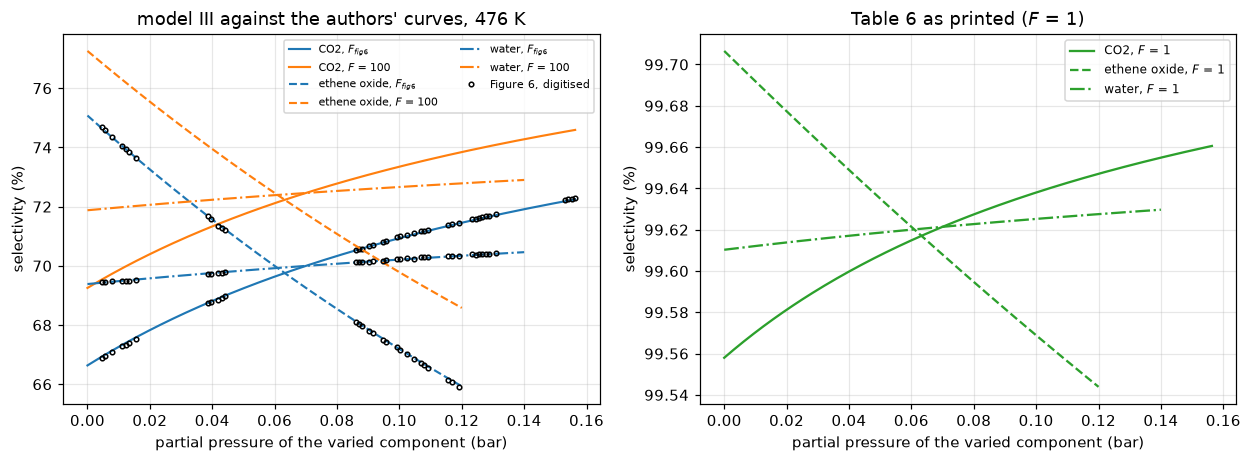

As printed ($F = 1$), model III gives 99.62 % at the caption condition and 99.55 to 99.70 % along the three curves, where the digitised points of the authors' own curves span 65.9 to 74.7 %: 0 of 105 digitised points lie within the reading band of 0.08 points. Fitted over all points, $F_{fig6}$ = 112.78 (per curve: CO2 112.72, ethene oxide 112.89, water 112.75; spread 0.15 %), with a root mean square residual of 0.031 points and a largest residual of 0.084: 104 of 105 points lie within the band. One factor on the combustion rate constant reproduces all three curves. $F = 100$ leaves a mean offset of +2.46 points (0 of 105 inside the band). Taking $F = 100$ and the temperature free instead, the best fit is at 485.3 K with a root mean square of 0.20 points (12 of 105 inside): the caption temperature with a factor near 113 fits, the factor 100 at another temperature does not. Under the lump form of the rate constants the fit gives 112.59.

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
style = {"C": ("-", "CO2"), "EO": ("--", "ethene oxide"), "W": ("-.", "water")}
for c, (ls, lab) in style.items():
    p = np.linspace(0.0, max(RANGE[c], FIG6.P_bar[FIG6.curve == c].max()), 200)
    for FF, col, tag in ((M["F_fig6"], "C0", r"$F_{fig6}$"), (100.0, "C1", "$F$ = 100")):
        s = 100 * selectivity(*rates(PARS, T_FIG, fig6_pressures(c, p), FF))
        ax[0].plot(p, s, ls, color=col, lw=1.4, label=f"{lab}, {tag}")
    pts = FIG6[FIG6.curve == c]
    ax[0].plot(pts.P_bar, pts.selectivity_pct, "o", ms=3, mfc="none", color="k")
    s1 = 100 * selectivity(*rates(PARS, T_FIG, fig6_pressures(c, p), 1.0))
    ax[1].plot(p, s1, ls, color="C2", label=f"{lab}, $F$ = 1")
ax[0].plot([], [], "o", ms=3, mfc="none", color="k", label="Figure 6, digitised")
ax[0].set(xlabel="partial pressure of the varied component (bar)", ylabel="selectivity (%)",
          title="model III against the authors' curves, 476 K")
ax[0].legend(fontsize=7, ncol=2)
ax[1].set(xlabel="partial pressure of the varied component (bar)", ylabel="selectivity (%)",
          title="Table 6 as printed ($F$ = 1)")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

ntot = len(FIG6)
say("As printed ($F = 1$), model III gives <<s1:.2f>> % at the caption condition and "
    "<<lo:.2f>> to <<hi:.2f>> % along the three curves, where the digitised points of the authors' own curves span "
    "<<ylo:.1f>> to <<yhi:.1f>> %: <<i1:d>> of <<n:d>> digitised points lie within the reading "
    "band of <<band:g>> points. Fitted over all points, $F_{fig6}$ = <<F:.2f>> (per curve: CO2 "
    "<<fc:.2f>>, ethene oxide <<feo:.2f>>, water <<fw:.2f>>; spread <<spr:.2f>> %), with a root "
    "mean square residual of <<rms:.3f>> points and a largest residual of <<mx:.3f>>: "
    "<<ifit:d>> of <<n:d>> points lie within the band. One factor on the combustion rate "
    "constant reproduces all three curves. $F = 100$ leaves a mean offset of <<m100:+.2f>> "
    "points (<<i100:d>> of <<n:d>> inside the band). Taking $F = 100$ and the temperature free "
    "instead, the best fit is at <<tf:.1f>> K with a root mean square of <<rtf:.2f>> points "
    "(<<itf:d>> of <<n:d>> inside): the caption temperature with a factor near <<F:.0f>> fits, "
    "the factor 100 at another temperature does not. Under the lump form of the rate "
    "constants the fit gives <<fl:.2f>>.",
    s1=M["sigma_T_F1_pct"], lo=M["fig6_F1_min_pct"], hi=M["fig6_F1_max_pct"],
    ylo=FIG6.selectivity_pct.min(), yhi=FIG6.selectivity_pct.max(), i1=M["fig6_inside_F1"],
    n=ntot, band=BAND, F=M["F_fig6"], fc=M["F_fig6_C"], feo=M["F_fig6_EO"], fw=M["F_fig6_W"],
    spr=100 * M["F_fig6_curve_spread"], rms=M["fig6_rms_Ffit"], mx=M["fig6_maxdev_Ffit"],
    ifit=M["fig6_inside_Ffit"], m100=M["fig6_mean_F100"], i100=M["fig6_inside_F100"],
    tf=M["T_free_F100"], rtf=M["fig6_rms_F100_Tfree"], itf=M["fig6_inside_F100_Tfree"],
    fl=M["F_fig6_lumpform"])

**Readings of the factor that do not restore the printed constants.** Three further
readings are computed. The deactivation factors $f_3$ of Table 6 refer later series to
series 1 (eq. 6), so they scale $r_2/r_1$ by $f_3(r_2)/f_3(r_1)$ or its inverse. Models I
and II of Table 5 are evaluated with their printed constants and no factor. The printed
476 K adsorption constants replace the pairs $(K_\infty, T_{ads})$ in a refit of $F$.

In [8]:
say("No other reading restores the printed constants: the deactivation factors refer "
    "later series to series 1 (eq. 6) and move $r_2/r_1$ by <<a:.3f>> or <<b:.3f>> "
    "(selectivity <<s1:.2f>> or <<s2:.2f>> % at the caption condition, against <<s0:.2f>> %); "
    "models I and II as printed miss the curves (root mean square <<r1:.2f>> and <<r2:.2f>> "
    "points, <<ni:d>> of the <<n:d>> digitised points within the band for either). The ratio "
    "100 $f_3(r_1)/f_3(r_2)$ = <<q:.1f>> matches the factor, but its rounding interval, "
    "<<lo:.1f>> to <<hi:.1f>>, covers all <<nf:d>> factors the printed forms give (the "
    "caption form, the lump form and the printed 476 K adsorption constants), so it cannot "
    "be tested; the page does not adopt it as the cause. With the printed 476 K adsorption "
    "constants in place of the pairs the fit gives $F$ = <<fk:.1f>>, against <<F:.1f>>.",
    a=M["f3_factor"], b=M["f3_factor_inv"], s1=M["sigma_T_f3_pct"], s2=M["sigma_T_f3inv_pct"],
    s0=M["sigma_T_F1_pct"], r1=M["fig6_rms_modelI"], r2=M["fig6_rms_modelII"],
    ni=M["fig6_inside_modelsI_II"], n=len(FIG6), q=M["f3_ratio_x100"],
    lo=M["f3_ratio_x100_lo"], hi=M["f3_ratio_x100_hi"], nf=M["f3_interval_forms_inside"],
    fk=M["F_fig6_K476"], F=M["F_fig6"])

No other reading restores the printed constants: the deactivation factors refer later series to series 1 (eq. 6) and move $r_2/r_1$ by 0.886 or 1.128 (selectivity 99.66 or 99.57 % at the caption condition, against 99.62 %); models I and II as printed miss the curves (root mean square 3.55 and 1.52 points, 0 of the 105 digitised points within the band for either). The ratio 100 $f_3(r_1)/f_3(r_2)$ = 112.8 matches the factor, but its rounding interval, 110.1 to 115.6, covers all 3 factors the printed forms give (the caption form, the lump form and the printed 476 K adsorption constants), so it cannot be tested; the page does not adopt it as the cause. With the printed 476 K adsorption constants in place of the pairs the fit gives $F$ = 112.4, against 112.8.

**The trends.** The sign of $\partial\sigma/\partial P_j$ is the sign of
$\partial\ln(r_1/r_2)/\partial P_j = -2K_j^1/D_1 + 2K_j^2/D_2$, in which the factor on
$r_2$ does not appear: the trend signs hold for any $F$. They are evaluated at every
digitised point and on the Table 3 range of each component.

In [9]:
say("At every point: CO2 <<sc>> (smallest magnitude <<mc:.3f>> 1/bar), ethene oxide "
    "<<seo>> (<<meo:.3f>> 1/bar), water <<sw>> (<<mw:.3f>> 1/bar); at the caption point "
    "<<dc:.3f>>, <<deo:.3f>> and <<dw:.3f>> 1/bar. CO2 raises and ethene oxide lowers the "
    "selectivity, as the paper states. For water the paper's argument, approximately equal "
    "adsorption constants, holds ($K_W^2/K_W^1$ = <<kw:.3f>>), but the combustion sites are "
    "less covered ($D_2/D_1$ = <<dd:.3f>>), so water raises the selectivity: by <<wr:.2f>> "
    "points over 0 to <<pw:g>> bar at $F_{fig6}$, which the paper calls hardly affecting it "
    "and its own Figure 6 shows as a rising line. The oxygen orders at the caption point are "
    "<<no1:.3f>> (epoxidation) and <<no2:.3f>> (combustion), the \"near zero order behavior "
    "in oxygen partial pressure\" of p. 54; the ethene orders are <<ne1:.3f>> and <<ne2:.3f>>.",
    sc=M["sign_C"], mc=M["sign_margin_C"], seo=M["sign_EO"], meo=M["sign_margin_EO"],
    sw=M["sign_W"], mw=M["sign_margin_W"], dc=M["dlnratio_dPC_T"], deo=M["dlnratio_dPEO_T"],
    dw=M["dlnratio_dPW_T"], kw=M["KW2_over_KW1"], dd=M["D2_over_D1"],
    wr=M["water_sigma_rise_pts"], pw=RANGE["W"], no1=M["nO1_T"], no2=M["nO2_T"],
    ne1=M["nE1_T"], ne2=M["nE2_T"])

At every point: CO2 positive (smallest magnitude 0.969 1/bar), ethene oxide negative (2.703 1/bar), water positive (0.279 1/bar); at the caption point 1.661, -3.596 and 0.359 1/bar. CO2 raises and ethene oxide lowers the selectivity, as the paper states. For water the paper's argument, approximately equal adsorption constants, holds ($K_W^2/K_W^1$ = 1.022), but the combustion sites are less covered ($D_2/D_1$ = 0.931), so water raises the selectivity: by 1.08 points over 0 to 0.14 bar at $F_{fig6}$, which the paper calls hardly affecting it and its own Figure 6 shows as a rising line. The oxygen orders at the caption point are 0.141 (epoxidation) and 0.158 (combustion), the "near zero order behavior in oxygen partial pressure" of p. 54; the ethene orders are 0.912 and 0.809.

### R3: the selectivity measured at the standard condition (Table 4)

Each Table 4 row is inverted through eqs. 1 and 2 for its conversions, Table 8 gives
its outlet composition, and model III at 500 K gives the selectivity there. Three runs
on fresh samples: no statistic is possible, and none is attempted.

In [10]:
rows = M["_rows"]
t4tab = pd.DataFrame({
    "experiment": [r["row"] for r in rows],
    "ethene conversion": [r["zE"] for r in rows],
    "P_E (bar)": [r["P"][0] for r in rows], "P_O (bar)": [r["P"][1] for r in rows],
    "measured sigma (%)": [100 * r["s_meas"] for r in rows],
    "model, F = 1 (%)": [100 * r["s_F1"] for r in rows],
    "model, F = 100 (%)": [100 * r["s_F100"] for r in rows],
    "model, F_fig6 (%)": [100 * r["s_F"] for r in rows],
    "F matching the row": [r["F_row"] for r in rows],
    "a2/a1 at F_fig6": [r["a2"] / r["a1"] for r in rows]})
show(t4tab, "c211r3", {c: "{:.4g}" for c in t4tab.columns if c != "experiment"})
say("The conversions are at most <<zmax:.3f>>, so the reactor runs at nearly the feed "
    "composition. Measured selectivities are <<s1:.2f>>, <<s2:.2f>> and <<s3:.2f>> %; Table 6 "
    "as printed gives <<m1:.2f>> % (row 2), $F = 100$ <<m100:.2f>> %, $F_{fig6}$ <<mf:.2f>> %. "
    "The factor that matches each row is <<f1:.1f>>, <<f2:.1f>> and <<f3:.1f>>, against "
    "$F_{fig6}$ = <<F:.1f>> from Figure 6; rows 2 and 3 are the two the paper calls equal in "
    "activity. In activity terms, with one factor $a_i = r_i/r_{i,model}$ per rate, $a_2/a_1$ "
    "is <<q1:.2f>>, <<q2:.2f>> and <<q3:.2f>> at $F_{fig6}$, where the paper's premise A2 (one "
    "factor on both rates) would make it 1. An O2 fraction of <<yo:g>> in the air instead of "
    "<<yo0:g>> moves the model selectivity of row 2 by <<do2:+.4f>> points. With <<xc:g>> % CO2 "
    "in the feed air instead of "
    "none (assumption A1), the model selectivity of row 2 moves by <<dco2:+.2f>> points and "
    "the factor matching row 2 becomes <<fco2:.1f>>.",
    zmax=M["zetaE_max"], s1=M["sigma_meas_row1_pct"], s2=M["sigma_meas_row2_pct"],
    s3=M["sigma_meas_row3_pct"], m1=M["sigma_T4_F1_pct"], m100=M["sigma_T4_F100_pct"],
    mf=M["sigma_T4_Ffit_pct"], f1=M["F_row1"], f2=M["F_row2"], f3=M["F_row3"], F=M["F_fig6"],
    q1=M["a2_over_a1_row1"], q2=M["a2_over_a1_row2"], q3=M["a2_over_a1_row3"],
    dco2=M["sigma_T4_CO2feed_shift_pts"], fco2=M["F_row2_CO2feed"], xc=100 * X_CO2_ALT,
    yo=Y_O2_ALT, yo0=Y_O2_AIR, do2=M["sigma_T4_O2_shift_pts"])
say("The forward Berty solve (pymrm) shows the point the paper makes on p. 53: in a stirred "
    "reactor a change of catalyst activity also changes the composition. Multiplying both "
    "activities of row 2 by a common factor moves the measured rates by <<e1:.3f>> ($r_1$) "
    "and <<e2:.3f>> ($r_2$) times as much, in relative terms (at $F_{fig6}$).",
    e1=M["elasticity_r1_row2"], e2=M["elasticity_r2_row2"])

experiment,ethene conversion,P_E (bar),P_O (bar),measured sigma (%),"model, F = 1 (%)","model, F = 100 (%)","model, F_fig6 (%)",F matching the row,a2/a1 at F_fig6
1,0.004807,0.08957,1.028,80,99.6,71.26,68.74,61.99,0.5497
2,0.01593,0.08858,1.027,70.95,99.6,71.1,68.56,100.7,0.8929
3,0.01521,0.08864,1.027,68.52,99.6,71.12,68.59,113.1,1.003


The conversions are at most 0.016, so the reactor runs at nearly the feed composition. Measured selectivities are 80.00, 70.95 and 68.52 %; Table 6 as printed gives 99.60 % (row 2), $F = 100$ 71.10 %, $F_{fig6}$ 68.56 %. The factor that matches each row is 62.0, 100.7 and 113.1, against $F_{fig6}$ = 112.8 from Figure 6; rows 2 and 3 are the two the paper calls equal in activity. In activity terms, with one factor $a_i = r_i/r_{i,model}$ per rate, $a_2/a_1$ is 0.55, 0.89 and 1.00 at $F_{fig6}$, where the paper's premise A2 (one factor on both rates) would make it 1. An O2 fraction of 0.21 in the air instead of 0.20946 moves the model selectivity of row 2 by -0.0050 points. With 0.04 % CO2 in the feed air instead of none (assumption A1), the model selectivity of row 2 moves by +0.12 points and the factor matching row 2 becomes 101.3.

The forward Berty solve (pymrm) shows the point the paper makes on p. 53: in a stirred reactor a change of catalyst activity also changes the composition. Multiplying both activities of row 2 by a common factor moves the measured rates by 0.952 ($r_1$) and 0.963 ($r_2$) times as much, in relative terms (at $F_{fig6}$).

### R4: temperature

The paper's two activation energies (quoted above) are $R\,(T_r)_{lump}$, the temperature dependence of the
numerator alone. The apparent activation energy of each rate at a composition also
carries the temperature dependence of the adsorption terms in $D_i^2$.

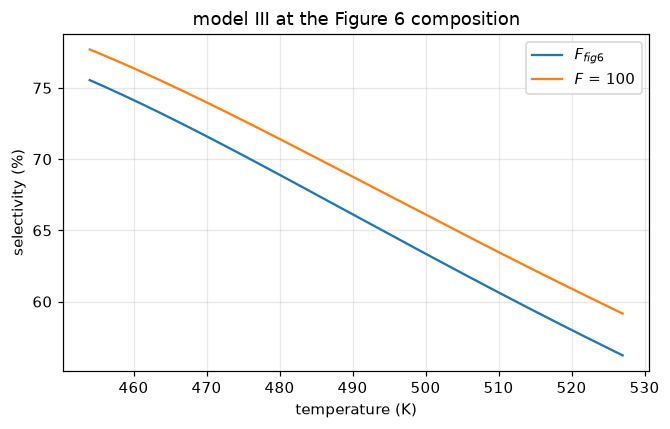

At the Figure 6 composition and 476 K, $E_{app}$ is 78.9 kJ/mol for epoxidation and 103.3 kJ/mol for combustion, against the lumped 70.8 and 87.1: the gap is 24.4 kJ/mol instead of 16.2. The factor on $r_2$ does not enter $E_{app}$, so the conclusion that the selectivity falls with temperature holds for any factor and is stronger than printed: $d\sigma/dT$ = -0.00272 1/K at $F_{fig6}$ and -0.00258 1/K at $F = 100$. Labelled illustration, not a reactor result: at fixed composition the selectivity changes by -2.75, -5.53 and -8.28 points at 10, 20 and 30 K above 476 K ($F_{fig6}$), and the 2 K gas-particle bound of p. 51 corresponds to rate shifts of 8.7 % ($r_1$) and 11.5 % ($r_2$).

In [11]:
Tg = np.linspace(454.0, 527.0, 147)
fig, ax = plt.subplots(figsize=(6.2, 4.0))
for FF, col, tag in ((M["F_fig6"], "C0", r"$F_{fig6}$"), (100.0, "C1", "$F$ = 100")):
    ax.plot(Tg, [100 * selectivity(*rates(PARS, t, P_FIG, FF))[()] for t in Tg], color=col,
            label=tag)
ax.set(xlabel="temperature (K)", ylabel="selectivity (%)",
       title="model III at the Figure 6 composition")
ax.legend()
plt.tight_layout()
plt.show()
say("At the Figure 6 composition and <<tf:g>> K, $E_{app}$ is <<e1:.1f>> kJ/mol for epoxidation "
    "and <<e2:.1f>> kJ/mol for combustion, against the lumped <<l1:.1f>> and <<l2:.1f>>: the "
    "gap is <<g:.1f>> kJ/mol instead of <<gl:.1f>>. The factor on $r_2$ does not enter $E_{app}$, "
    "so the conclusion that the selectivity falls with temperature holds for any factor and "
    "is stronger than printed: $d\\sigma/dT$ = <<d1:.5f>> 1/K at $F_{fig6}$ and <<d2:.5f>> 1/K at "
    "$F = 100$. Labelled illustration, not a reactor result: at fixed composition the "
    "selectivity changes by <<t10:.2f>>, <<t20:.2f>> and <<t30:.2f>> points at <<d1_:d>>, <<d2_:d>> "
    "and <<d3_:d>> K above <<tf:g>> K ($F_{fig6}$), and the <<dg:g>> K gas-particle bound of p. 51 "
    "corresponds to rate "
    "shifts of <<s1:.1f>> % ($r_1$) and <<s2:.1f>> % ($r_2$).",
    e1=M["Eapp1_T_kJmol"], e2=M["Eapp2_T_kJmol"], l1=M["Elump1_kJmol"], l2=M["Elump2_kJmol"],
    g=M["Eapp_gap_kJmol"], gl=M["Elump_gap_kJmol"], d1=M["dsigma_dT_Ffit"],
    d2=M["dsigma_dT_F100"], t10=M["dsigma_plus10K_pts"], t20=M["dsigma_plus20K_pts"],
    t30=M["dsigma_plus30K_pts"], s1=M["r1_shift_2K_pct"], s2=M["r2_shift_2K_pct"],
    d1_=DT_STEPS[0], d2_=DT_STEPS[1], d3_=DT_STEPS[2], tf=T_FIG,
    dg=printed("dT_gas_particle_max"))

### R5: ethene oxide oxidation (eq. 8)

The paper prints "The ratio r1/r3 has a value between 0 and 0.3" and concludes that
ethene oxide oxidation is negligible; that conclusion needs $r_3/r_1$, read here as
meant. The basis of $r_3$ (ethene oxide consumed or CO2 formed) is not stated.

In [12]:
say("At the Figure 6 condition eq. 8 gives $r_3/r_1$ = <<a:.3f>> (<<b:.3f>> if $r_3$ counts "
    "CO2 formed), outside the printed <<lo>> to <<hi>> (printed as $r_1/r_3$) on either basis. Eq. 8 was measured without "
    "ethene, and the paper itself expects $r_3$ to be much smaller under reaction conditions "
    "(competitive adsorption), which this page cannot test; it does not claim that ethene "
    "oxide oxidation matters.",
    a=M["r3_over_r1_T"], b=M["r3_over_r1_T_CO2basis"],
    lo=PN.loc["r3_ratio_text", "value"].split("-")[0],
    hi=PN.loc["r3_ratio_text", "value"].split("-")[1])

At the Figure 6 condition eq. 8 gives $r_3/r_1$ = 0.727 (0.364 if $r_3$ counts CO2 formed), outside the printed 0 to 0.3 (printed as $r_1/r_3$) on either basis. Eq. 8 was measured without ethene, and the paper itself expects $r_3$ to be much smaller under reaction conditions (competitive adsorption), which this page cannot test; it does not claim that ethene oxide oxidation matters.

## Validation

- **V1, derivatives.** The analytic $E_{app}$, $\partial\ln(r_1/r_2)/\partial P_j$ and
  the reaction orders against central differences on a ladder of relative steps $0.1/n$, $n = 1$ to 1024,
  with `pymrm.checks.observed_orders` (theory 2). Only triples whose finest difference
  exceeds 1e3 times the round-off companion $\epsilon\,|f|/h$ are used. The closed-form
  $d\sigma/dT$ against a central difference, and the closed-form $F$ against a
  `find_roots` root.
- **V2, Table 8.** A-4/A-5 recover the conversions from the outlet fractions, and the
  C, H and O balances close, at every Table 4 row.
- **V3, the forward Berty solve** (`newton`) returns the conversions of the explicit
  inversion at every row, at two tolerances, with the backward error of
  `residual_check`.
- **V4, caption form against lump form** at the Figure 6 condition, against what the
  rounding of the printed lump allows.
- **V5, check values** from a second route (above).

In [13]:
say("V1: <<nt:d>> triples in the asymptotic range give orders <<omin:.3f>> to <<omax:.3f>>; "
    "the analytic values and the finest usable differences agree to <<g:.1e>> relative "
    "(truncation at that step). $d\\sigma/dT$ closed form against a central difference: "
    "<<gT:.1e>> relative, below 1e-5 (the step of 1e-3 K). Closed-form $F$ against the "
    "root: <<gF:.0e>> relative, below 1e-10. "
    "V2: A-4/A-5 round trip and the C, H, O balances are at round-off, below 1e-13 (here "
    "<<rt:.0e>> and <<bal:.0e>>). "
    "V3: the forward solve returns the inverted conversions to below 1e-9 at both tolerances "
    "(here <<bg:.0e>>), backward error below 1e-12 (here <<bw:.0e>>). "
    "V4: the lump form differs from the caption form by <<l1:.2f>> % ($r_1$) and <<l2:.2f>> % "
    "($r_2$), at most <<lr:.2f>> of what the rounding of the printed lump and lumped "
    "temperature allows.",
    nt=M["V1_triples_used"], omin=M["V1_order_min"], omax=M["V1_order_max"],
    g=M["V1_analytic_vs_fd_max_relgap"], gT=M["dsigma_dT_closed_vs_fd_relgap"],
    gF=M["F70_closed_vs_root_relgap"], rt=M["a4a5_roundtrip_max_relgap"],
    bal=M["chobalance_max_relgap"], bg=M["berty_roundtrip_max_relgap"],
    bw=M["berty_backward_error_max"], l1=100 * M["lump_vs_caption_r1_relgap"],
    l2=100 * M["lump_vs_caption_r2_relgap"], lr=M["lump_gap_over_rounding_max"])

V1: 61 triples in the asymptotic range give orders 1.964 to 2.079; the analytic values and the finest usable differences agree to 4.4e-08 relative (truncation at that step). $d\sigma/dT$ closed form against a central difference: 2.6e-10 relative, below 1e-5 (the step of 1e-3 K). Closed-form $F$ against the root: 7e-16 relative, below 1e-10. V2: A-4/A-5 round trip and the C, H, O balances are at round-off, below 1e-13 (here 2e-14 and 2e-16). V3: the forward solve returns the inverted conversions to below 1e-9 at both tolerances (here 4e-16), backward error below 1e-12 (here 2e-16). V4: the lump form differs from the caption form by 0.12 % ($r_1$) and 0.05 % ($r_2$), at most 0.07 of what the rounding of the printed lump and lumped temperature allows.

In [14]:
# Claims: every number above, with how it is checked, and the break table.
cl = claims
# R1
cl.count("k476_pairs_off_rounding", M["_k476_half_units"], 1.0, min_margin=0.01,
         note="recomputed K(476) more than one half-unit of the printed entry away; exact "
              "arithmetic on printed strings, the margin guards against round-off only")
cl.count("k476_pairs_outside_interval", M["_k476_miss"], 0.0, min_margin=0.05,
         note="interval over the input rounding misses the printed rounding interval (half-units)")
cl.count("lumps_outside_interval", M["_lump_miss"], 0.0, min_margin=0.05,
         note="same test for the lumped constants")
cl.count("tlump_mismatches", M["_tlump_half_units"], 0.5, min_margin=0.5,
         note="T_act - T_ads,E against the printed lumped temperature, half-units")
cl.value("k476_half_units_max", M["k476_half_units_max"], unit="half-units")
for i in (1, 2):
    cl.value(f"Elump{i}_kJmol", M[f"Elump{i}_kJmol"], rtol=0.01, unit="kJ/mol")
    cl.value(f"Elump{i}_half_units_vs_print", M[f"Elump{i}_half_units_vs_print"],
             unit="half-units of the printed kJ/mol")
for name in ("I", "II", "III"):
    cl.value(f"lumpratio21_476_model{name}", M[f"lumpratio21_476_model{name}"])
# R2
cl.value("sigma_T_F1_pct", M["sigma_T_F1_pct"], rtol=0.005, unit="%")
cl.value("fig6_F1_min_pct", M["fig6_F1_min_pct"], rtol=0.005, unit="%")
cl.value("fig6_F1_max_pct", M["fig6_F1_max_pct"], rtol=0.005, unit="%")
cl.value("F_fig6", M["F_fig6"], rtol=0.01)
for c in ("C", "EO", "W"):
    cl.value(f"F_fig6_{c}", M[f"F_fig6_{c}"], rtol=0.01)
cl.bound("F_fig6_curve_spread", M["F_fig6_curve_spread"], max=0.01, basis="chosen",
         note="stop rule of the plan: one factor reads all three curves")
cl.bound("fig6_rms_Ffit", M["fig6_rms_Ffit"], max=0.1, basis="chosen",
         unit="selectivity points", note="stop rule: the one-factor reading fails above 0.1")
cl.value("fig6_maxdev_Ffit", M["fig6_maxdev_Ffit"], rtol=0.2, unit="selectivity points")
cl.exact("fig6_n_points", int(len(FIG6)), structural=True,
         note="rows of the committed digitised CSV; no break row can change the data file")
cl.count("fig6_inside_Ffit", BAND - np.abs(M["_fig6_dev_Ffit"]), 0.0, min_margin=0.002,
         note="points within the reading band at F_fig6")
cl.count("fig6_inside_F1", BAND - np.abs(M["_fig6_dev_F1"]), 0.0, min_margin=0.002,
         note="points within the reading band at F = 1")
cl.count("fig6_inside_F100", BAND - np.abs(M["_fig6_dev_F100"]), 0.0, min_margin=0.002,
         note="points within the reading band at F = 100")
cl.value("fig6_mean_F100", M["fig6_mean_F100"], rtol=0.05, unit="selectivity points")
cl.value("T_free_F100", M["T_free_F100"], rtol=0.002, unit="K")
cl.value("fig6_rms_F100_Tfree", M["fig6_rms_F100_Tfree"], rtol=0.1, unit="selectivity points")
cl.count("fig6_inside_F100_Tfree", BAND - np.abs(M["_fig6_dev_F100_Tfree"]), 0.0,
         min_margin=0.002, note="points within the reading band at F = 100, T fitted")
cl.value("F_fig6_lumpform", M["F_fig6_lumpform"], rtol=0.01)
cl.value("F_fig6_K476", M["F_fig6_K476"], rtol=0.001,
         note="fit with the printed 476 K adsorption constants in place of the pairs")
cl.value("sigma_T_f3_pct", M["sigma_T_f3_pct"], rtol=5e-4, unit="%",
         note="r2/r1 multiplied by f3(r2)/f3(r1)")
cl.value("sigma_T_f3inv_pct", M["sigma_T_f3inv_pct"], rtol=5e-4, unit="%",
         note="r2/r1 multiplied by f3(r1)/f3(r2)")
cl.value("f3_factor", M["f3_factor"], rtol=0.01, note="f3(r2)/f3(r1), printed")
cl.value("f3_factor_inv", M["f3_factor_inv"], rtol=0.01, note="f3(r1)/f3(r2), printed")
cl.value("f3_ratio_x100", M["f3_ratio_x100"], rtol=0.01)
cl.value("f3_ratio_x100_lo", M["f3_ratio_x100_lo"], rtol=0.01)
cl.value("f3_ratio_x100_hi", M["f3_ratio_x100_hi"], rtol=0.01)
cl.count("f3_interval_forms_inside", M["_f3_forms_margin"], 0.0, min_margin=0.5,
         note="factors of the three printed forms inside the rounding interval of the f3 ratio")
for name in ("I", "II"):
    cl.value(f"fig6_rms_model{name}", M[f"fig6_rms_model{name}"], rtol=0.05,
             unit="selectivity points", note=f"model {name} as printed, no factor")
cl.count("fig6_inside_modelsI_II", M["_fig6_margin_modelsI_II"], 0.0, min_margin=0.002,
         note="points within the reading band for model I or model II as printed")
for c in ("C", "EO", "W"):
    cl.exact(f"sign_{c}", M[f"sign_{c}"], margin=M[f"sign_margin_{c}"], min_margin=0.05)
    cl.value(f"dlnratio_dP{c}_T", M[f"dlnratio_dP{c}_T"], unit="1/bar")
cl.value("water_sigma_rise_pts", M["water_sigma_rise_pts"], rtol=0.1, unit="selectivity points")
cl.value("KW2_over_KW1", M["KW2_over_KW1"], rtol=0.005)
cl.value("D2_over_D1", M["D2_over_D1"], rtol=0.005)
for q in ("nO1_T", "nO2_T", "nE1_T", "nE2_T"):
    cl.value(q, M[q], rtol=0.01)
# R3
cl.value("zetaE_max", M["zetaE_max"])
for k in (1, 2, 3):
    cl.value(f"sigma_meas_row{k}_pct", M[f"sigma_meas_row{k}_pct"], rtol=0.005, unit="%")
    cl.value(f"F_row{k}", M[f"F_row{k}"], rtol=0.01)
    cl.value(f"a2_over_a1_row{k}", M[f"a2_over_a1_row{k}"], rtol=0.02)
cl.value("sigma_T4_F1_pct", M["sigma_T4_F1_pct"], rtol=0.005, unit="%")
cl.value("sigma_T4_F100_pct", M["sigma_T4_F100_pct"], rtol=0.005, unit="%")
cl.value("sigma_T4_Ffit_pct", M["sigma_T4_Ffit_pct"], rtol=0.005, unit="%")
cl.value("sigma_T4_CO2feed_shift_pts", M["sigma_T4_CO2feed_shift_pts"], rtol=0.1,
         unit="selectivity points", note="0.04 % CO2 in the feed air against none (A1)")
cl.value("F_row2_CO2feed", M["F_row2_CO2feed"], rtol=0.01)
cl.value("sigma_T4_O2_shift_pts", M["sigma_T4_O2_shift_pts"], rtol=0.1,
         unit="selectivity points", note="O2 fraction of air 0.21 against 0.20946 (A1)")
cl.value("elasticity_r1_row2", M["elasticity_r1_row2"], rtol=0.005)
cl.value("elasticity_r2_row2", M["elasticity_r2_row2"], rtol=0.005)
# R4
for q in ("Eapp1_T_kJmol", "Eapp2_T_kJmol", "Eapp_gap_kJmol", "Elump_gap_kJmol"):
    cl.value(q, M[q], rtol=0.01, unit="kJ/mol")
cl.value("dsigma_dT_Ffit", M["dsigma_dT_Ffit"], rtol=0.02, unit="1/K")
cl.value("dsigma_dT_F100", M["dsigma_dT_F100"], rtol=0.02, unit="1/K")
for dT in DT_STEPS:
    cl.value(f"dsigma_plus{dT}K_pts", M[f"dsigma_plus{dT}K_pts"], rtol=0.02,
             unit="selectivity points")
cl.value("r1_shift_2K_pct", M["r1_shift_2K_pct"], rtol=0.02, unit="%")
cl.value("r2_shift_2K_pct", M["r2_shift_2K_pct"], rtol=0.02, unit="%")
# R5
cl.value("r3_over_r1_T", M["r3_over_r1_T"], rtol=0.01)
cl.value("r3_over_r1_T_CO2basis", M["r3_over_r1_T_CO2basis"], rtol=0.01)
# Validation
cl.bound("V1_order_min", M["V1_order_min"], min=1.9, max=2.1, basis="theory")
cl.bound("V1_order_max", M["V1_order_max"], min=1.9, max=2.1, basis="theory")
cl.exact("V1_triples_used", M["V1_triples_used"])
cl.bound("V1_analytic_vs_fd_max_relgap", M["V1_analytic_vs_fd_max_relgap"], max=1e-6,
         basis="theory", note="central-difference truncation at the finest usable step")
cl.bound("dsigma_dT_closed_vs_fd_relgap", M["dsigma_dT_closed_vs_fd_relgap"], max=1e-5,
         basis="theory", note="central difference with a 1e-3 K step")
cl.bound("F70_closed_vs_root_relgap", M["F70_closed_vs_root_relgap"], max=1e-10,
         basis="tolerance", note="find_roots xtol 1e-12 on a root near 113")
cl.bound("a4a5_roundtrip_max_relgap", M["a4a5_roundtrip_max_relgap"], max=1e-13,
         basis="identity")
cl.bound("chobalance_max_relgap", M["chobalance_max_relgap"], max=1e-13, basis="identity")
cl.bound("berty_roundtrip_max_relgap", M["berty_roundtrip_max_relgap"], max=1e-9,
         basis="tolerance", note="newton tol 1e-10 and 1e-12 on unknowns scaled to order one")
cl.bound("berty_backward_error_max", M["berty_backward_error_max"], max=1e-12,
         basis="tolerance")
cl.value("lump_vs_caption_r1_relgap", M["lump_vs_caption_r1_relgap"], rtol=0.05)
cl.value("lump_vs_caption_r2_relgap", M["lump_vs_caption_r2_relgap"], rtol=0.05)
cl.bound("lump_gap_over_rounding_max", M["lump_gap_over_rounding_max"], max=1.0,
         basis="chosen", note="the gap is inside what the printed rounding allows")
cl.bound("check_values_worst_reldev", M["check_values_worst_reldev"], max=1e-11,
         basis="tolerance", note="the rtol of every check-value row")

In [15]:
def t6_edit(model, rx, prm, new):
    """Table 6 with one printed entry replaced (a misreading)."""
    t = T6.copy()
    i = t.index[(t.model == model) & (t.reaction == rx) & (t.parameter == prm)][0]
    return t, i, new


def t6_with(model, rx, prm, new):
    t, i, new = t6_edit(model, rx, prm, new)
    t.at[i, "value"] = new
    return t


def t6_swap_products():
    """Table 6 with the r1 and r2 columns of the product constants of model III swapped."""
    t = T6.copy()
    names = {f"K_{j}" for j in PRODUCTS_} | {f"K_{j}_inf" for j in PRODUCTS_} \
        | {f"T_ads_{j}" for j in PRODUCTS_}
    m = (t.model == "III") & t.parameter.isin(names)
    t.loc[m, "reaction"] = t.loc[m, "reaction"].map({"r1": "r2", "r2": "r1"})
    return t


PRODUCTS_ = ("C", "EO", "W")
T4_SWAP = T4.copy()
T4_SWAP[["r1_1e-6_mol_per_kg_s", "r2_1e-6_mol_per_kg_s"]] = \
    T4[["r2_1e-6_mol_per_kg_s", "r1_1e-6_mol_per_kg_s"]].to_numpy()
T4_W10 = T4.copy()
T4_W10["W_g"] = (T4.W_g.astype(float) * 10).map(lambda v: f"{v:.0f}")
PN_EQ8 = PN.copy()
PN_EQ8.loc["eq8_order", "value"] = "0.04"
PN_FEED = PN.copy()
PN_FEED.loc["table4_feed_ethene", "value"] = "18"

ROWS = [
    ("control: clean rerun", lambda: study()),
    ("r2 factor fixed at 1 (Table 6 as printed)", lambda: study(F_fix=1.0)),
    ("r2 factor fixed at 100", lambda: study(F_fix=100.0)),
    ("selectivity without the factor 1/2, r1/(r1 + r2)", lambda: study(half=False)),
    ("adsorption constants frozen at 476 K in D", lambda: study(frozen=True)),
    ("Figure 6 evaluated at 485 K", lambda: study(T_fig=485.0)),
    ("Table 6 r2 k_inf 1.08e8 read as 1.22e10", lambda: study(t6=t6_with("III", "r2", "k_inf", "1.22e10"))),
    ("Table 6 r2 K_E,inf 4.0e-3 read as 4.0e-2", lambda: study(t6=t6_with("III", "r2", "K_E_inf", "4.0e-2"))),
    ("Table 6 model I r2 k_lump 7.02e7 read as 7.02e6", lambda: study(t6=t6_with("I", "r2", "k_lump", "7.02e6"))),
    ("Table 6 model II r2 K_E,inf 5.30e-3 read as 5.80e-3", lambda: study(t6=t6_with("II", "r2", "K_E_inf", "5.80e-3"))),
    ("dsigma/dT from the lumped activation energies", lambda: study(e_source="lump")),
    ("closed-form F with r1/(r1 + r2), root with the factor 1/2", lambda: study(closed_half=False)),
    ("forward Berty solve at newton tol 1e-2, step test only",
     lambda: study(berty_tols=(1e-2,), berty_btol=None)),
    ("Table 6 r1 and r2 product constants swapped (model III)", lambda: study(t6=t6_swap_products())),
    ("Table 6 r2 K_W,inf 0.109 read as 0.098", lambda: study(t6=t6_with("III", "r2", "K_W_inf", "0.098"))),
    ("Table 6 r1 K_E,inf 2.05e-7 read as 2.50e-7", lambda: study(t6=t6_with("III", "r1", "K_E_inf", "2.50e-7"))),
    ("Table 6 r1 T_ads,W 840 read as 940", lambda: study(t6=t6_with("III", "r1", "T_ads_W", "940"))),
    ("Table 6 model I r2 K_W,inf 4.04e-2 read as 4.40e-2", lambda: study(t6=t6_with("I", "r2", "K_W_inf", "4.40e-2"))),
    ("Table 6 model II r1 k_lump 9.1e6 read as 9.7e6", lambda: study(t6=t6_with("II", "r1", "k_lump", "9.7e6"))),
    ("Table 6 r1 T_lump 8520 read as 8250", lambda: study(t6=t6_with("III", "r1", "T_lump", "8250"))),
    ("Table 6 r2 T_act 14650 read as 16450", lambda: study(t6=t6_with("III", "r2", "T_act", "16450"))),
    ("Table 6 r2 T_lump 10470 read as 11470", lambda: study(t6=t6_with("III", "r2", "T_lump", "11470"))),
    ("Table 6 r2 K_C 98.5 read as 89.5", lambda: study(t6=t6_with("III", "r2", "K_C", "89.5"))),
    ("Table 6 r2 f3 0.39 read as 0.93", lambda: study(t6=t6_with("III", "r2", "f3", "0.93"))),
    ("Table 6 model I r2 k_inf 1.42e6 read as 1.42e5", lambda: study(t6=t6_with("I", "r2", "k_inf", "1.42e5"))),
    ("Table 6 model II r2 k_inf 8.1e9 read as 7.6e9", lambda: study(t6=t6_with("II", "r2", "k_inf", "7.6e9"))),
    ("Table 6 r1 K_O 84.8 read as 48.8", lambda: study(t6=t6_with("III", "r1", "K_O", "48.8"))),
    ("Table 6 r1 k_lump 8.9e6 read as 9.8e6", lambda: study(t6=t6_with("III", "r1", "k_lump", "9.8e6"))),
    ("Table 4 r1 and r2 columns swapped", lambda: study(t4=T4_SWAP)),
    ("Table 4 catalyst mass in units of 0.1 g", lambda: study(t4=T4_W10)),
    ("feed 18 % ethene, not 1.8 %", lambda: study(pn=PN_FEED)),
    ("eq. 8 order 0.4 read as 0.04", lambda: study(pn=PN_EQ8)),
    ("one-sided differences in V1", lambda: study(scheme="forward")),
    ("Table 8 O2 use 3 per zeta_C on top of 1/2 per zeta_E", lambda: study(o2_per_zC=3.0)),
    ("A-4/A-5 without the change in total moles", lambda: study(contraction=False)),
    ("forward Berty solve with a1 on both rates", lambda: study(berty_a2_is_a1=True)),
]
claims.define_rows([label for label, _ in ROWS])
BREAK, CRASH = [], []
for label, run in ROWS:
    try:
        with np.errstate(all="ignore"), contextlib.redirect_stdout(io.StringIO()):
            Mb, pb = run()
            cvb = check_values(Mb, pb)
            Mb["check_values_worst_reldev"] = max(
                abs(cvb[r.name] / r.value - 1.0)
                for r in load_data("check_values.csv", page=PAGE).itertuples())
    except (ValueError, RuntimeError, IndexError, KeyError, ZeroDivisionError) as e:
        CRASH.append(f"{label}: {type(e).__name__}: {e}")
        continue
    for name in claims.metrics:
        if claims.metrics[name].get("structural") or name not in Mb:
            continue
        x = Mb[name]
        if isinstance(x, (float, np.floating)) and not np.isfinite(x):
            continue                       # only finite values are recorded
        BREAK.append((label, name, claims.breaks(label, name, x)))
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
assert not any(by_row.get("control: clean rerun", [])), ("the control row failed a claim", [m_ for r_, m_, c_ in BREAK if c_ and r_.startswith("control")])
bt = pd.DataFrame([(r_, sum(cs), len(cs)) for r_, cs in by_row.items()],
                  columns=["injected defect", "claims failed", "claims recorded"])
show(bt, "c211bt")
caught = {m_ for r_, m_, c_ in BREAK if c_}
open_ = sorted(k for k in claims.metrics if k not in caught
               and not claims.metrics[k].get("structural"))
print(f"rows that crashed: {'; '.join(CRASH) or 'none'}")
print(f"{len(ROWS)} rows; {len(caught)} of {len(claims.metrics)} claims are failed by at least "
      f"one row; open: {', '.join(open_) or 'none'}")

injected defect,claims failed,claims recorded
control: clean rerun,0,100
r2 factor fixed at 1 (Table 6 as printed),20,100
r2 factor fixed at 100,17,100
"selectivity without the factor 1/2, r1/(r1 + r2)",22,100
adsorption constants frozen at 476 K in D,12,100
Figure 6 evaluated at 485 K,44,100
Table 6 r2 k_inf 1.08e8 read as 1.22e10,42,99
"Table 6 r2 K_E,inf 4.0e-3 read as 4.0e-2",53,100
Table 6 model I r2 k_lump 7.02e7 read as 7.02e6,3,100
"Table 6 model II r2 K_E,inf 5.30e-3 read as 5.80e-3",4,100


rows that crashed: none
36 rows; 100 of 101 claims are failed by at least one row; open: none


### The finding

In [16]:
WORD = {"positive": "raises", "negative": "lowers", "changes sign": "changes the sign of"}
say("As printed, model III gives <<s1:.2f>> % selectivity at the Figure 6 condition and "
    "<<s4:.2f>> % at the Table 4 condition, where the digitised points of the authors' own model III curves lie at "
    "<<ylo:.1f>> to <<yhi:.1f>> % (<<i1:d>> of <<n:d>> digitised points within the reading "
    "band) and the measured selectivities are <<m1:.1f>>, <<m2:.1f>> and <<m3:.1f>> %. What the "
    "numbers show: the model III combustion rate constant, in both of its printed forms, is "
    "smaller by a factor of <<F:.1f>> (<<fk:.1f>> to <<F:.1f>> over the printed forms of the "
    "constants) than the paper's own Figure 6 requires. With that one "
    "factor all three curves are reproduced: root mean square <<rms:.3f>> points, largest "
    "residual <<mx:.3f>>, <<ifit:d>> of <<n:d>> points within the reading band of <<band:g>> "
    "points, the three per-curve factors within <<spr:.2f>> % of each other. The Table 4 runs, "
    "on other catalyst samples, need <<f1:.1f>>, <<f2:.1f>> and <<f3:.1f>>. The trend signs do "
    "not depend on the factor: CO2 <<wc>> the selectivity, ethene oxide <<weo>> it and water "
    "<<ww>> it. Nor does the fall of the selectivity with temperature: at the Figure 6 "
    "composition the apparent activation energies are <<e1:.1f>> and <<e2:.1f>> kJ/mol, "
    "against the printed <<p1:g>> and <<p2:g>>. Eq. 8 gives $r_3/r_1$ = <<r3:.3f>>, against "
    "the printed range <<lo>> to <<hi>> (printed as $r_1/r_3$).",
    s1=M["sigma_T_F1_pct"], s4=M["sigma_T4_F1_pct"], ylo=FIG6.selectivity_pct.min(),
    yhi=FIG6.selectivity_pct.max(), i1=M["fig6_inside_F1"], n=len(FIG6),
    m1=M["sigma_meas_row1_pct"], m2=M["sigma_meas_row2_pct"], m3=M["sigma_meas_row3_pct"],
    F=M["F_fig6"], fk=M["F_fig6_K476"], rms=M["fig6_rms_Ffit"], mx=M["fig6_maxdev_Ffit"],
    ifit=M["fig6_inside_Ffit"], band=BAND, spr=100 * M["F_fig6_curve_spread"], f1=M["F_row1"], f2=M["F_row2"],
    f3=M["F_row3"], wc=WORD[M["sign_C"]], weo=WORD[M["sign_EO"]], ww=WORD[M["sign_W"]],
    e1=M["Eapp1_T_kJmol"], e2=M["Eapp2_T_kJmol"], p1=printed("E_app_epoxidation"),
    p2=printed("E_app_combustion"), r3=M["r3_over_r1_T"],
    lo=PN.loc["r3_ratio_text", "value"].split("-")[0],
    hi=PN.loc["r3_ratio_text", "value"].split("-")[1])

As printed, model III gives 99.62 % selectivity at the Figure 6 condition and 99.60 % at the Table 4 condition, where the digitised points of the authors' own model III curves lie at 65.9 to 74.7 % (0 of 105 digitised points within the reading band) and the measured selectivities are 80.0, 71.0 and 68.5 %. What the numbers show: the model III combustion rate constant, in both of its printed forms, is smaller by a factor of 112.8 (112.4 to 112.8 over the printed forms of the constants) than the paper's own Figure 6 requires. With that one factor all three curves are reproduced: root mean square 0.031 points, largest residual 0.084, 104 of 105 points within the reading band of 0.08 points, the three per-curve factors within 0.15 % of each other. The Table 4 runs, on other catalyst samples, need 62.0, 100.7 and 113.1. The trend signs do not depend on the factor: CO2 raises the selectivity, ethene oxide lowers it and water raises it. Nor does the fall of the selectivity with temperature: at the Figure 6 composition the apparent activation energies are 78.9 and 103.3 kJ/mol, against the printed 70 and 86. Eq. 8 gives $r_3/r_1$ = 0.727, against the printed range 0 to 0.3 (printed as $r_1/r_3$).

## What pymrm adds

Little, and that is the honest answer for this page: the science is the rate law, its
derivatives and an explicit inversion of the gradientless reactor, all closed form.
pymrm contributes the forward solve of that reactor (`pymrm.newton` on scaled unknowns
with a `NumJac` Jacobian, judged by `pymrm.checks.residual_check`), which validates the
inversion of Table 4 and measures how the measured rates respond to the catalyst
activity; `pymrm.checks.find_roots` for the closed-form factor check; and
`pymrm.checks.observed_orders` for the finite-difference ladders that test the analytic
derivatives. The finding itself, that Table 6 as printed does not produce the paper's
own Figure 6 or its measured selectivities and that one factor on the combustion rate
constant restores all three Figure 6 curves, needs no solver.

## Reuse

- **The r2 factor.** Model III with Table 6 as printed gives nearly complete
  selectivity at the Figure 6 and Table 4 conditions. To reproduce the authors' own curves, multiply the
  combustion rate constant by $F_{fig6}$ (claim `F_fig6` in this page's
  `agreement.json`; `D3.5` should load it with `load_claims`, not retype it). $F = 100$
  is not a substitute: it misses Figure 6 by the offset shown above. Say which factor
  you use; the paper does not print one.
- **Temperature.** Use the full apparent activation energies at the composition of
  interest, not the lumped values the paper prints: the gap between the two reactions is larger
  at the Figure 6 composition, so the selectivity falls faster with temperature.
- **Activity.** Table 4 shows that samples of one catalyst differ in activity, and not
  always by one factor on both rates (row 1). Fit the activity of your own sample.
- **Structure.** A 0-D gradientless reactor (S1): change `model.table6_params` for
  another rate law, keep `BertyReactor` for the forward solve.
- Related pages: `D3.5` (planned: the multitubular reactor with this kinetics), `C2.10`
  (hot spot in a cooled fixed bed), `C2.1` (parity and refit of a fitted kinetics),
  `C2.13` (an integral reactor against the authors' calculated curves), `C1.1`
  (Langmuir-Hinshelwood forms).

In [17]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C2.11:
  k476_pairs_off_rounding       = 10               exact  exact, margin 0.0177
  k476_pairs_outside_interval   = 0                exact  exact, margin 3.11
  lumps_outside_interval        = 0                exact  exact, margin 1.09
  tlump_mismatches              = 0                exact  exact, margin 1
  k476_half_units_max           = 9.6123           value  rtol 0.05
  Elump1_kJmol                  = 70.839           value  rtol 0.01
  Elump1_half_units_vs_print    = 1.6784           value  rtol 0.05
  Elump2_kJmol                  = 87.052           value  rtol 0.01
  Elump2_half_units_vs_print    = 2.1048           value  rtol 0.05
  lumpratio21_476_modelI        = 0.7706           value  rtol 0.05
  lumpratio21_476_modelII       = 0.73371          value  rtol 0.05
  lumpratio21_476_modelIII      = 0.0065953        value  rtol 0.05
  sigma_T_F1_pct                = 99.621           value  rtol 0.005
  fig6_F1_min_pct               = 99.545           value  rtol